# How prompt bans move an LLM's path-search choices: demo notebook

**Artifact:** a behavioural and activation-space screen of **Qwen3-8B** (bf16, thinking off, temperature 1.0) on path-search coding tasks. This demo covers task **T1 (grid path)**: the model writes `solve(grid, start, goal)`, and a validated labeller decides which algorithm it implemented. The catalogue has 6 modes: `bfs`, `dfs`, `bidir_bfs`, `iddfs`, `astar` and `dijkstra_unit`.

**The question.** Asked for a path-search program, does the model always write the "average" answer (BFS)? If a prompt *bans* that answer, where does the probability mass go? Can the geometry of the model's own activations predict where it lands?

**What the full run found (T1):**
* **The baseline collapses completely.** All 200/200 baseline programs are BFS, and `mention:bfs` keeps 50/50 BFS.
* **The ban mostly fails.** `ban:bfs` gives 62 BFS, 29 DFS and 9 unit-cost Dijkstra, so compliance is only 0.18.
* **The displaced mass goes to BFS's geodesic neighbours.** On the read-position manifold, BFS's two nearest centroids are DFS (geodesic distance 41) and unit-Dijkstra (58), and the mass that leaves BFS lands only there. It never reaches the far side: A* (71), IDDFS (82) or bidirectional BFS (95).
* **Forecasts were hash-committed before any ban sample was drawn.** On the primary events, geodesic proximity has the best mean log score (−1.43, against −1.56 for uniform). The model's own ranking of "the most standard alternative" is the worst predictor (−2.59).

**What this notebook runs (CPU only).** It runs the CPU stages of `method.py` on a curated subset of 100 generated programs (`mini_demo_data.json`), using the original code split into cells:
1. the stage plan of `method.py`;
2. the prompts, rebuilt from their templates;
3. the sandboxed hidden-test runner plus the runtime-trace and AST labeller, which re-labels programs from scratch;
4. the Phase-A summary and the Phase-C ban event;
5. the read-position manifold (PCA95, then a kNN graph, geodesics and MDS), its TwoNN intrinsic dimension, and the geodesic and decoder forecasts;
6. the analysis figures and the scoring of the forecast contest.

**What it loads instead of recomputing.** Anything that needs Qwen3-8B (16 GB) on a GPU: the 100 generated programs and their layer-27 read-position activations `h_R`. It also loads three outputs of the full run: its final labels (an LLM judge settled some of them), its per-layer probe gate, and its committed forecasts. The activation-removal arm (Phase D) is only summarised.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the original pipeline logs with loguru 0.7.3)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- original import block of method.py
import argparse
import json
import subprocess
import sys
import time
from pathlib import Path

# ---- imports of the stage modules whose CPU parts run below (common.py, prompts/build_prompts.py,
#      tasks/tasklib.py, labeller/rules.py, labeller/label.py, labeller/run_label_a.py, gen/phase_c.py,
#      analysis/geometry.py, hf/phase_b.py, analysis/analyze.py)
import ast
import asyncio
import hashlib
import io
import itertools
import math
import os
import random
import re
import shutil
import tempfile
import threading
import tokenize
from collections import Counter, deque
from concurrent.futures import ThreadPoolExecutor
from typing import Any, Iterable

import numpy as np
from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse.csgraph import connected_components, minimum_spanning_tree, shortest_path
from scipy.spatial.distance import cdist

# ---- notebook addition: inline figures
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-1/experiment-2/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# The copy at GITHUB_DATA_URL can lag behind this notebook (an older demo file at the same path until the repository
# is updated). If it does not have this notebook's layout, use the local mini_demo_data.json instead.
if "datasets" not in data and Path("mini_demo_data.json").exists():
    print("GitHub copy has a different layout; using the local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
EXAMPLES = data["datasets"][0]["examples"]
print(data["metadata"]["description"])
print(f"\n{len(EXAMPLES)} programs per condition:", dict(Counter(e["metadata_condition"] for e in EXAMPLES)))
print("example fields:", [k for k in EXAMPLES[0]])
print(f"h_R: {len(EXAMPLES[0]['metadata_hR_l27'])} floats per program (layer {data['metadata']['hR_layer']})")

GitHub copy has a different layout; using the local mini_demo_data.json
Demo subset of artifact art_D6Z0Snf09sFL (path-search ban screen on Qwen3-8B, bf16, thinking off, T=1.0). Task T1 (grid path, solve(grid, start, goal)) only. Each example is one generated program with its prompt, its labels from the full run, and the model's read-position residual state h_R at layer 27 for that prompt.

100 programs per condition: {'forced:bfs': 10, 'forced:dfs': 10, 'forced:bidir_bfs': 10, 'forced:iddfs': 10, 'forced:astar': 10, 'forced:dijkstra_unit': 10, 'baseline': 10, 'ban:bfs': 20, 'mention:bfs': 10}
example fields: ['input', 'output', 'predict_mode_label', 'predict_passed', 'predict_compliant', 'metadata_phase', 'metadata_condition', 'metadata_paraphrase_id', 'metadata_sample_id', 'metadata_prompt_id', 'metadata_frame_id', 'metadata_model', 'metadata_decoding', 'metadata_labeller_source', 'metadata_rt_label', 'metadata_ast_label', 'metadata_wall_s', 'metadata_fail_kind', 'metadata_code_sha25

## Configuration
Every parameter that sets how much work the notebook does is defined here, with the original full-run value in the comment. The demo data caps two of them: `LABEL_N` at 100 programs and `N_FORCED_PER_MODE` at 10 forced prompts per mode (the full run used 30). `KNN_K` is a method parameter, so it stays at its original value.

**Runtime.** With the values below, the notebook ran in about 3 minutes on 2 CPU cores. About 2.6 of those minutes are the sandboxed re-labelling of 100 programs (1.6 s per program). Colab's CPUs are slower, so expect roughly twice that there. Set `LABEL_N` lower (for example 18, which is 2 programs per condition) for a run of about a minute; nothing downstream depends on it.

In [5]:
# Demo configuration (original full-run values in the comments)
TASKS = ["t1"]           # tasks analysed (original: ["t1", "t2"]; the demo data holds task T1 only)
LABEL_N = 100            # programs re-labelled from scratch by the sandboxed tests + runtime tracer + AST rules
                         #   (original: every generated program, 2310; demo max 100)
LABEL_WORKERS = 2        # threads launching the sandbox subprocesses (original: 6, the CPU count of the run machine)
USE_JUDGE = False        # blind LLM judge for programs where runtime and AST disagree (original: True; needs
                         #   OPENROUTER_API_KEY and OPENROUTER_BASE_URL; the full run's judge calls cost about $0.09 in total)
N_FORCED_PER_MODE = 10   # forced (named) prompt states per mode that span the manifold (original: 30; demo max 10;
                         #   min 3, because the decoder probe keeps len(points) - 12 PCs)
KNN_K = 10               # degree of the symmetric kNN graph (original: 10)
N_BOOT = 1000            # bootstrap resamples for the stability of the forecasts (original: 1000)
N_TWONN_NULLS = 20       # column-shuffled nulls for the TwoNN intrinsic dimension (original: 20)
MDS_N_INIT = 4           # MDS restarts (original: 4)

## 1. `method.py`: the pipeline entry point
`method.py` runs 12 stages, each as its own process, because a process exit frees the GPU memory. The forecasts are **hash-committed at the end of Phase B**, before any ban or removal sample exists, and Phases C and D refuse to start if the hash does not match.

The cell below is the original script. Its `main()` runs as a **dry run** that only lists the stage commands. Running the GPU stages needs the full repository, Qwen3-8B, and about 2.2 h on an NVIDIA L4. The sections after it run the CPU parts of these stages inline:

| stage | what it does | in this notebook |
|---|---|---|
| `tasks` | hidden tests; every catalogue reference passes 3/3; deliberately wrong programs fail | test generator and sandbox (§3) |
| `labtests` | labeller unit tests | not run (19/19 in the full run) |
| `prompts`, `succession` | builds every prompt with its token ids | prompt text rebuilt from the templates (§2) |
| `phase_a` | samples baseline N=200 and forced 30 per mode (GPU) | programs loaded from the data |
| `label_a` | labeller, labeller gate, Phase-A summary | labeller re-run (§4); summary (§5) |
| `phase_b` | `h_R` states (GPU), then R gate, manifold and **commit** | states loaded; manifold and forecasts recomputed (§6) |
| `phase_c` | prompt bans, N=100 (GPU) | samples loaded; event summary (§5) |
| `phase_d` | affine directional ablation (GPU) | summarised in §8 |
| `analysis` | summaries, manifold figures, contest | run (§7) |

In [6]:
# ---- method.py: "Entry point: the full path-search ban screen on Qwen3-8B (thinking off), stage by stage."
# Notebook changes: ROOT is this notebook's folder (original: the artifact folder that holds the stage scripts);
# the logger writes to stdout only (original: common.setup_logger also writes logs/<name>.log); modal_arg() reads
# the Phase-A summary shipped in `data`; main() takes its CLI arguments as a list and, with dry_run=True, only
# lists the stage commands (the stage scripts and the 16 GB model are not part of this demo).
from loguru import logger

ROOT = Path.cwd()
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
PY = str(ROOT / ".venv" / "bin" / "python")


def modal_arg() -> list[str]:
    s = data["metadata"]["phaseA_summary"]  # original: json.loads((ROOT / "results" / "phaseA_summary.json").read_text())
    return ["--modal", ",".join(f"{t}={s[t]['modal']}" for t in TASKS)]


STAGES = [
    ("tasks", lambda: [PY, "tasks/tasklib.py"]),
    ("labtests", lambda: [PY, "labeller/test_labeller.py"]),
    ("prompts", lambda: [PY, "prompts/build_prompts.py"]),
    ("phase_a", lambda: [PY, "gen/phase_a.py", "--batch", "32"]),
    ("label_a", lambda: [PY, "labeller/run_label_a.py"]),
    ("succession", lambda: [PY, "prompts/build_prompts.py"] + modal_arg()),
    ("phase_b", lambda: [PY, "hf/phase_b.py"]),
    ("phase_c", lambda: [PY, "gen/phase_c.py", "--deadline-min", "45"]),
    ("phase_d", lambda: [PY, "hf/phase_d.py"]),
    ("phase_c_ext", lambda: [PY, "gen/phase_c_ext.py"]),
    ("phase_d_ext", lambda: [PY, "hf/phase_d.py", "--exploratory-full"]),
    ("analysis", lambda: [PY, "analysis/analyze.py"]),
]


@logger.catch(reraise=True)
def main(argv: list[str] | None = None, dry_run: bool = True) -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--from", dest="start", default="tasks")
    ap.add_argument("--only", default=None)
    args = ap.parse_args(argv or [])
    names = [n for n, _ in STAGES]
    todo = [args.only] if args.only else names[names.index(args.start):]
    for name, cmd in STAGES:
        if name not in todo:
            continue
        c = cmd()
        logger.info(f"=== stage {name}: {' '.join(x.replace(str(ROOT), '.') for x in c)}")
        if dry_run:  # notebook: list the plan only
            continue
        t0 = time.time()
        r = subprocess.run(c, cwd=str(ROOT))
        logger.info(f"=== stage {name} exit {r.returncode} in {(time.time() - t0) / 60:.1f} min")
        if r.returncode != 0:
            raise RuntimeError(f"stage {name} failed with exit code {r.returncode}")


main(dry_run=True)

11:04:45|INFO   |=== stage tasks: ./.venv/bin/python tasks/tasklib.py


11:04:45|INFO   |=== stage labtests: ./.venv/bin/python labeller/test_labeller.py


11:04:45|INFO   |=== stage prompts: ./.venv/bin/python prompts/build_prompts.py


11:04:45|INFO   |=== stage phase_a: ./.venv/bin/python gen/phase_a.py --batch 32


11:04:45|INFO   |=== stage label_a: ./.venv/bin/python labeller/run_label_a.py


...

11:04:45|INFO   |=== stage phase_c: ./.venv/bin/python gen/phase_c.py --deadline-min 45


11:04:45|INFO   |=== stage phase_d: ./.venv/bin/python hf/phase_d.py


11:04:45|INFO   |=== stage phase_c_ext: ./.venv/bin/python gen/phase_c_ext.py


11:04:45|INFO   |=== stage phase_d_ext: ./.venv/bin/python hf/phase_d.py --exploratory-full


11:04:45|INFO   |=== stage analysis: ./.venv/bin/python analysis/analyze.py


## 2. Task specification, catalogue and prompt templates (`common.py`, `prompts/build_prompts.py`)
Every condition shares one task specification. A condition-specific clause is placed in front of it, wrapped in one of 10 **frames** (the paraphrases). The conditions are:
* `baseline`: no instruction about the algorithm;
* `forced:X`: names the algorithm X;
* `masked:X`: describes X without naming it;
* `ban:X`: forbids X;
* `mention:X`: names X as one option among any correct algorithm;
* `listall`: names every algorithm in the catalogue.

Every prompt ends with the same suffix tokens. The read position **R** is the last prompt token: the `"\n\n"` after Qwen3's empty `<think></think>` block, which is there because thinking is off.

In [7]:
# ---- common.py: "Shared constants, task specs, catalogue, prompt templates and helpers for the path-search ban screen."
# Verbatim, except: TASKS is set in the config cell, and the helpers that only manage the repository's folders
# (compiler-cache env vars, read/write_jsonl, setup_logger, log_timing, add_deviation, resource limits) are omitted.
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_TAG = "Qwen3-8B-bf16"
DECODING_GEN = "T=1.0,top_p=1.0,top_k=off,min_p=0,max_tokens=1024,thinking=off,stop=closing_fence"
DECODING_HOOK = "T=1.0,top_p=1.0,top_k=off,max_new_tokens=768,thinking=off,hooked_hf,stop=closing_fence"

TASK_DATASET = {"t1": "t1_grid_path", "t2": "t2_weighted_sp"}
CACHE_LAYERS = list(range(8, 29))  # l = output of decoder block l = hidden_states[l + 1]
N_LAYERS_MODEL = 36

SPEC = {
    "t1": (
        "Write a Python function solve(grid, start, goal). grid is a list of equal-length strings over . (free) "
        "and # (wall), at most 30 rows and 30 columns; start and goal are (row, col) tuples of free cells. A move "
        "goes to one of the 4 orthogonal neighbours inside the grid. Return any valid path from start to goal as a "
        "list of (row, col) tuples including both endpoints, or [] if the goal is unreachable. Return only one "
        "```python code block containing the function and its imports."
    ),
    "t2": (
        "Write a Python function solve(n, edges, s, t). Nodes are 0..n-1 with n <= 100; edges is a list of directed "
        "(u, v, w) triples with integer weights 0 <= w <= 100, at most 1000 edges; cycles, self-loops and parallel "
        "edges may occur. Return the length of the shortest path from s to t, or -1 if t is unreachable. Return only "
        "one ```python code block containing the function and its imports."
    ),
}

CATALOGUE: dict[str, list[str]] = {
    "t1": ["bfs", "dfs", "bidir_bfs", "iddfs", "astar", "dijkstra_unit"],
    "t2": ["dijkstra", "bellman_ford_spfa", "bidir_dijkstra", "floyd_warshall", "dial"],
}

DISPLAY: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bidir_bfs": "bidirectional BFS",
        "iddfs": "iterative-deepening DFS (IDDFS)",
        "astar": "A* search with a Manhattan-distance heuristic",
        "dijkstra_unit": "Dijkstra's algorithm",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bellman_ford_spfa": "Bellman-Ford (or SPFA)",
        "bidir_dijkstra": "bidirectional Dijkstra",
        "floyd_warshall": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}

ONE_LINE_DEF: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search: FIFO queue, level-by-level expansion from the start only",
        "dfs": "depth-first search: LIFO stack or recursion following one route deep and backtracking (no growing depth limit)",
        "bidir_bfs": "bidirectional BFS: two FIFO frontiers, one from the start and one from the goal, until they meet",
        "iddfs": "iterative-deepening DFS: depth-limited DFS restarted with limits 0,1,2,... until the goal is found",
        "astar": "A* (or greedy best-first): priority queue ordered by cost-so-far plus (or only) Manhattan distance to the goal",
        "dijkstra_unit": "Dijkstra with unit weights: priority queue (heap) ordered by step count only, no heuristic",
    },
    "t2": {
        "dijkstra": "Dijkstra: one binary heap (or repeated minimum selection) of tentative distances from the source",
        "bellman_ford_spfa": "Bellman-Ford (repeated sweeps over all edges) or SPFA (FIFO queue of improved nodes, no heap)",
        "bidir_dijkstra": "bidirectional Dijkstra: forward search from s and backward search from t on reversed edges",
        "floyd_warshall": "Floyd-Warshall: all-pairs n x n distance matrix with a triple loop over intermediate nodes",
        "dial": "Dial's algorithm: array of buckets indexed by integer distance scanned in increasing order, no heap",
    },
}

DESCRIPTIONS: dict[str, dict[str, list[str]]] = {
    "t1": {
        "bfs": [
            "explore cells in order of their step distance from the start, level by level, with a first-in-first-out queue",
            "expand the search outward one ring of equal step count at a time, always processing the earliest-discovered cell next",
            "keep a first-in-first-out frontier of discovered cells and record each cell's predecessor the first time it is reached",
        ],
        "dfs": [
            "follow one route as deep as possible and backtrack with a last-in-first-out stack or recursion",
            "keep extending the current route to an unvisited neighbour and step back only when the route gets stuck",
            "always continue from the most recently discovered cell, retreating to an earlier branch point at dead ends",
        ],
        "bidir_bfs": [
            "grow two level-by-level frontiers, one from the start and one from the goal, until they meet",
            "search outward from both endpoints at the same time, one ring of cells per round, and join the two halves where they touch",
            "alternate expanding a first-in-first-out frontier around the start and another around the goal, stopping when a cell is reached from both sides",
        ],
        "iddfs": [
            "repeat a depth-limited deep-first search with limits 0, 1, 2, ... until the goal is found",
            "run a deep-first search that may not exceed a maximum route length, and restart it with a larger maximum each time it fails",
            "combine deep-first exploration with a step budget that grows by one after every unsuccessful complete pass",
        ],
        "astar": [
            "always expand the cell with the smallest steps-so-far plus Manhattan distance to the goal",
            "rank frontier cells by the route length so far plus the row and column distance remaining to the goal, and expand the best-ranked one",
            "use a priority queue ordered by cost-so-far plus an optimistic estimate of the remaining distance (absolute row difference plus absolute column difference)",
        ],
        "dijkstra_unit": [
            "keep a min-priority queue of tentative step counts and settle the cell with the smallest one",
            "repeatedly take the cell with the smallest known distance from a heap, finalize it, and lower its neighbours' distances",
            "maintain tentative distances to every cell and always finalize the closest unfinalized cell, taken from a heap, updating its neighbours",
        ],
    },
    "t2": {
        "dijkstra": [
            "settle the unsettled node with the smallest tentative distance from a min-priority queue and relax its outgoing edges",
            "grow a set of finalized nodes by always finalizing the closest remaining node, taken from a heap, and updating its neighbours",
            "keep tentative distances in a binary heap and repeatedly pop the minimum, skipping stale entries, and lower the distances of its successors",
        ],
        "bellman_ford_spfa": [
            "relax every edge repeatedly, or the edges of nodes whose distance just improved kept in a queue, until nothing changes",
            "sweep over the full edge list again and again, lowering any distance that an edge can improve, for at most n-1 rounds",
            "start with only the source distance known and keep improving distances by passing over all edges until a full pass makes no change",
        ],
        "bidir_dijkstra": [
            "run the smallest-tentative-distance settling process forward from the source and backward from the target on reversed edges until they meet",
            "search from both ends at once, settling nodes by distance from the source and by distance to the target on reversed edges, and stop when the two searches cannot improve the best meeting point",
            "alternate between a forward heap-based search from the source and a backward heap-based search from the target over reversed edges, combining them at the meeting node",
        ],
        "floyd_warshall": [
            "fill an all-pairs distance matrix by letting each node in turn act as an intermediate point",
            "build an n by n table of distances and improve every entry through each possible intermediate node with three nested loops",
            "compute distances between all pairs of nodes with dynamic programming over the allowed intermediate nodes, then read off the source-to-target entry",
        ],
        "dial": [
            "keep buckets indexed by integer tentative distance and scan them in increasing order",
            "place nodes into a list of buckets, one per possible integer distance, and process the buckets from the smallest distance upward",
            "exploit the small integer weights with an array of lists indexed by distance value instead of a heap, sweeping the array in increasing order",
        ],
    },
}

# Ten frames shared by every framed condition; frame f wraps the core clause of paraphrase f.
FRAMES = [
    "{core}",
    "Here is a programming exercise. {core}",
    "{core} Keep the code concise.",
    "Read the task below carefully. {core}",
    "{core} Make sure the code is correct.",
    "Consider the problem below. {core}",
    "{core} Write clean, readable Python.",
    "A coding task follows. {core}",
    "{core} Aim for a correct and efficient program.",
    "Your assignment is described below. {core}",
]
BASELINE_CORES = [
    "Solve the following programming task.",
    "Please solve the task below.",
    "Complete the following coding task.",
    "Solve this programming problem.",
    "Write a solution to the following task.",
    "Solve the task described below.",
    "Here is a task for you to solve.",
    "Please complete the programming task below.",
    "Solve the following problem in Python.",
    "Write code that solves the task below.",
]
FORCED_CORES = ["Implement {X} for this task.", "Solve this task using {X}.", "Write a solution based on {X}."]
MASKED_CORE = "Solve this task with the following approach: {D}."
BAN_CORES = [
    "Do not use {X}.",
    "You must not use {X}.",
    "Avoid {X} entirely.",
    "Your solution must not use {X}.",
    "Do not implement {X}.",
    "Using {X} is not allowed.",
    "Do not base your solution on {X}.",
    "{X} is forbidden for this task.",
    "Please do not use {X}.",
    "Stay away from {X}.",
]
MENTION_CORES = [
    "{X} is one well-known approach to this task; implement any correct algorithm.",
    "{X} is one standard way to solve this; you may implement any correct algorithm.",
    "{X} is a common approach here; implement any correct algorithm.",
    "{X} is one known approach; your solution may use any correct algorithm.",
    "{X} is one familiar technique for this; implement any correct algorithm.",
    "{X} is one possible approach; any correct algorithm is allowed.",
    "{X} is one approach people use for this; implement any correct algorithm.",
    "{X} is one option for this task; implement any correct algorithm.",
    "{X} is one well-known approach; please implement any correct algorithm.",
    "{X} is one widely used approach; implement any correct algorithm.",
]
LISTALL_CORE = "Known approaches include {LIST}; implement any correct algorithm."
ELICIT_TEMPLATE = (
    "For the task below, rank the following approaches by how standard an alternative to {X} they are for this task, "
    "most standard first. Approaches: {NAMES}. Answer with only a JSON list of the names exactly as written."
)
N_PARA = 10


def join_names(names: list[str]) -> str:
    """'a', 'a or b', 'a, b or c' (used inside ban cores)."""
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " or " + names[-1]


def join_names_and(names: list[str]) -> str:
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " and " + names[-1]


def frame(f: int, core: str) -> str:
    return FRAMES[f].format(core=core)


def user_message(condition_segment: str, task: str) -> str:
    return condition_segment + "\n\n" + SPEC[task]


def stable_seed(*parts: Any) -> int:
    h = hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest()
    return int(h[:8], 16) % (2**31 - 1)


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def append_jsonl(p: Path, rows: Iterable[dict]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("a") as fh:
        for r in rows:
            fh.write(json.dumps(r) + "\n")


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (0.0, 1.0)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def hill1(counts: dict[str, int]) -> float:
    """Hill number of order 1 = exp(Shannon entropy) over label counts."""
    tot = sum(v for v in counts.values() if v > 0)
    if tot == 0:
        return 0.0
    H = -sum((v / tot) * math.log(v / tot) for v in counts.values() if v > 0)
    return math.exp(H)


def js_div(p: dict[str, float] | list[float], q: dict[str, float] | list[float], keys: list[str] | None = None) -> float:
    """Jensen-Shannon divergence (base 2, in [0, 1])."""
    import numpy as np

    if isinstance(p, dict):
        keys = keys or sorted(set(p) | set(q))
        pa = np.array([p.get(k, 0.0) for k in keys], float)
        qa = np.array([q.get(k, 0.0) for k in keys], float)
    else:
        pa, qa = np.asarray(p, float), np.asarray(q, float)
    pa = pa / pa.sum() if pa.sum() > 0 else pa
    qa = qa / qa.sum() if qa.sum() > 0 else qa
    m = 0.5 * (pa + qa)

    def kl(a, b):
        mask = a > 0
        return float(np.sum(a[mask] * np.log2(a[mask] / b[mask])))

    return 0.5 * kl(pa, m) + 0.5 * kl(qa, m)


def condition_banset(cond: str) -> list[str]:
    if cond.startswith("ban:"):
        return cond.split(":", 1)[1].split("+")
    if cond.startswith("removal:"):
        return [cond.split(":", 1)[1]]
    return []


print("T1 catalogue:", CATALOGUE["t1"])
print("T1 task spec:", SPEC["t1"])

T1 catalogue: ['bfs', 'dfs', 'bidir_bfs', 'iddfs', 'astar', 'dijkstra_unit']
T1 task spec: Write a Python function solve(grid, start, goal). grid is a list of equal-length strings over . (free) and # (wall), at most 30 rows and 30 columns; start and goal are (row, col) tuples of free cells. A move goes to one of the 4 orthogonal neighbours inside the grid. Return any valid path from start to goal as a list of (row, col) tuples including both endpoints, or [] if the goal is unreachable. Return only one ```python code block containing the function and its imports.


`build_rows` creates every prompt of the screen. Forced and masked prompts use 30 paraphrases per mode (10 frames × 3 core variants). Ban, mention and listall prompts use 10 paraphrases each, and the succession bans cover every ordered set of 2–3 modes that starts with the modal mode.

In the original `build_prompts.py`, the next steps apply Qwen3's chat template (`enable_thinking=False`), store the token ids, and assert that the suffix ids are identical across conditions. Those steps need the Qwen tokenizer, so they are skipped here. Instead, the cell below checks that the rebuilt text equals the prompt stored with every demo program.

In [8]:
# ---- prompts/build_prompts.py: build_rows() (verbatim). The original main() then tokenises every row with Qwen3's
#      chat template, asserts identical suffix ids per task and writes prompts/prompts.jsonl (needs the tokenizer).
ELICIT_TAIL = "Remember: answer with only the JSON list of approach names, not code."
N_ELICIT = 20


def build_rows(modal: dict[str, str]) -> list[dict]:
    rows: list[dict] = []

    def add(task: str, cond: str, para: int, seg: str, kind: str, **extra) -> None:
        rows.append({"task": task, "condition": cond, "paraphrase_id": para, "kind": kind,
                     "text": seg + "\n\n" + SPEC[task], **extra})

    for task in TASKS:
        modes = CATALOGUE[task]
        disp = DISPLAY[task]
        for p in range(N_PARA):
            add(task, "baseline", p, frame(p, BASELINE_CORES[p]), "geom", frame_id=p)
        for x in modes:
            for f in range(N_PARA):
                for v, core in enumerate(FORCED_CORES):
                    add(task, f"forced:{x}", f * 3 + v, frame(f, core.format(X=disp[x])), "geom", frame_id=f, variant_id=v)
                for v, desc in enumerate(DESCRIPTIONS[task][x]):
                    add(task, f"masked:{x}", f * 3 + v, frame(f, MASKED_CORE.format(D=desc)), "geom", frame_id=f, variant_id=v)
            for p in range(N_PARA):
                add(task, f"ban:{x}", p, frame(p, BAN_CORES[p].format(X=disp[x])), "geom", frame_id=p)
                add(task, f"mention:{x}", p, frame(p, MENTION_CORES[p].format(X=disp[x])), "geom", frame_id=p)
        for p in range(N_PARA):
            names = [disp[m] for m in modes]
            rot = names[p % len(names):] + names[: p % len(names)]
            add(task, "listall", p, frame(p, LISTALL_CORE.format(LIST=join_names_and(rot))), "geom", frame_id=p)
        # association elicitation: 20 samples per X, fresh random order of the K-1 other names per sample
        for x in modes:
            others = [m for m in modes if m != x]
            for s in range(N_ELICIT):
                rng = random.Random(stable_seed("elicit_order", task, x, s))
                order = others[:]
                rng.shuffle(order)
                names = ", ".join(disp[m] for m in order)
                seg = ELICIT_TEMPLATE.format(X=disp[x], NAMES=names)
                rows.append({"task": task, "condition": f"elicit:{x}", "paraphrase_id": s, "kind": "elicit",
                             "text": seg + "\n\n" + SPEC[task] + "\n\n" + ELICIT_TAIL, "order": order})
        # succession prompts (ordered cumulative ban sets starting with the modal mode)
        if task in modal:
            m0 = modal[task]
            rest = [m for m in modes if m != m0]
            seqs = [(m0, a) for a in rest] + [(m0, a, b) for a, b in itertools.permutations(rest, 2)]
            for seq in seqs:
                cond = "ban:" + "+".join(seq)
                for p in range(N_PARA):
                    add(task, cond, p, frame(p, BAN_CORES[p].format(X=join_names([disp[m] for m in seq]))), "geom",
                        frame_id=p)
    return rows


prompt_rows = build_rows(modal={t: data["metadata"]["phaseA_summary"][t]["modal"] for t in TASKS})
for r in prompt_rows:
    r["prompt_id"] = f"{r['task']}|{r['condition']}|p{r['paraphrase_id']:02d}"  # the id format of build_prompts.main()
prompts_by_id = {r["prompt_id"]: r for r in prompt_rows}
print(f"{len(prompt_rows)} T1 prompts:", dict(Counter(r["condition"].split(":")[0] for r in prompt_rows)))
n_same = sum(prompts_by_id[e["metadata_prompt_id"]]["text"] == e["input"] for e in EXAMPLES)
print(f"rebuilt prompt text == stored prompt text for {n_same}/{len(EXAMPLES)} demo programs\n")
for pid in ("t1|baseline|p00", "t1|forced:astar|p13", "t1|masked:astar|p13", "t1|ban:bfs|p03", "t1|mention:bfs|p01",
            "t1|ban:bfs+dfs|p00"):
    print(f"{pid:<21} {prompts_by_id[pid]['text'].split(chr(10))[0]}")

870 T1 prompts: {'baseline': 10, 'forced': 180, 'masked': 180, 'ban': 310, 'mention': 60, 'listall': 10, 'elicit': 120}
rebuilt prompt text == stored prompt text for 100/100 demo programs

t1|baseline|p00       Solve the following programming task.
t1|forced:astar|p13   Solve this task using A* search with a Manhattan-distance heuristic. Make sure the code is correct.
t1|masked:astar|p13   Solve this task with the following approach: rank frontier cells by the route length so far plus the row and column distance remaining to the goal, and expand the best-ranked one. Make sure the code is correct.
t1|ban:bfs|p03        Read the task below carefully. Your solution must not use breadth-first search (BFS).
t1|mention:bfs|p01    Here is a programming exercise. breadth-first search (BFS) is one standard way to solve this; you may implement any correct algorithm.
t1|ban:bfs+dfs|p00    Do not use breadth-first search (BFS) or depth-first search (DFS).


## 3. Hidden tests and the sandbox (`tasks/tasklib.py`, `tasks/harness.py`)
T1 has **41 hidden tests**: corner cases, carved mazes, and random walls on grids up to 30×30. Each test's time limit is `max(1 s, 10 × the slowest catalogue reference)`.

A generated program is never imported into this kernel. It runs in a fresh `python -I` subprocess with a 2 GB address-space limit, per-test `itimer` limits, fail-fast behaviour and a hard kill. The same harness has a **trace** mode: it runs the program on 3 small probe grids and records how the program uses its data structures:
* `heapq`, `deque` and `queue`;
* lists, and whether items are popped from the front or the back;
* recursion depth, how often the start cell is re-expanded, and line counts.

The next cell writes the harness script to `tasks/harness.py`, exactly as it appears in the repository.

In [9]:
# ---- tasks/tasklib.py: "Hidden tests, probe inputs and the sandboxed runner" (T1 generators, probes, runner; verbatim).
# Notebook changes: ROOT is this notebook's folder, and load_tests() reads the shipped hidden tests from `data`
# (original: tasks/hidden_tests_t1.json). main() (time every reference 3x, set limits, check that wrong programs fail)
# needs tasks/references.py and is not run.
TASK_DIR = ROOT / "tasks"
HARNESS = TASK_DIR / "harness.py"
SANDBOX = ROOT / "sandbox"
PY = sys.executable
TASK_DIR.mkdir(exist_ok=True)

# ------------------------------------------------------------------------------------------ T1 generators


def bfs_dist(grid: list[str], start: tuple[int, int]) -> dict[tuple[int, int], int]:
    R, C = len(grid), len(grid[0])
    d = {tuple(start): 0}
    q = deque([tuple(start)])
    while q:
        r, c = q.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == "." and (nr, nc) not in d:
                d[(nr, nc)] = d[(r, c)] + 1
                q.append((nr, nc))
    return d


def _free_cells(grid):
    return [(r, c) for r in range(len(grid)) for c in range(len(grid[0])) if grid[r][c] == "."]


def _random_grid(rng, R, C, p):
    g = [["#" if rng.random() < p else "." for _ in range(C)] for _ in range(R)]
    return g


def _maze(rng, R, C):
    """Recursive-backtracker maze on an R x C grid (odd cells are rooms)."""
    g = [["#"] * C for _ in range(R)]
    sr, sc = 0, 0
    g[sr][sc] = "."
    stack = [(sr, sc)]
    while stack:
        r, c = stack[-1]
        nbrs = [(r + dr, c + dc, r + dr // 2, c + dc // 2) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
                if 0 <= r + dr < R and 0 <= c + dc < C and g[r + dr][c + dc] == "#"]
        if not nbrs:
            stack.pop()
            continue
        nr, nc, wr, wc = rng.choice(nbrs)
        g[wr][wc] = "."
        g[nr][nc] = "."
        stack.append((nr, nc))
    return g


def _t1_case(grid_rows, start, goal, name):
    grid = ["".join(r) if not isinstance(r, str) else r for r in grid_rows]
    d = bfs_dist(grid, start)
    return {"name": name, "args": [grid, list(start), list(goal)], "reachable": tuple(goal) in d,
            "shortest": d.get(tuple(goal), -1)}


def build_t1_tests(seed: int = 1) -> list[dict]:
    rng = random.Random(seed)
    T = []
    T.append(_t1_case(["."], (0, 0), (0, 0), "1x1"))
    g = ["." * 7 for _ in range(5)]
    T.append(_t1_case(g, (2, 3), (2, 3), "start_eq_goal"))
    g = [list("." * 8) for _ in range(8)]
    for r, c in ((5, 6), (6, 5), (6, 7), (7, 6)):
        g[r][c] = "#"
    T.append(_t1_case(g, (0, 0), (6, 6), "unreachable_walled_goal"))
    g = [list("." * 10) for _ in range(10)]
    for c in range(10):
        g[5][c] = "#"
    T.append(_t1_case(g, (0, 0), (9, 9), "unreachable_split"))
    # snake corridor
    R, C = 15, 15
    g = [["#"] * C for _ in range(R)]
    for r in range(0, R, 2):
        for c in range(C):
            g[r][c] = "."
        if r + 1 < R:
            g[r + 1][C - 1 if (r // 2) % 2 == 0 else 0] = "."
    T.append(_t1_case(g, (0, 0), (R - 1, 0 if ((R - 1) // 2) % 2 == 1 else C - 1), "snake_corridor"))
    T.append(_t1_case(["." * 30 for _ in range(30)], (0, 0), (29, 29), "open_30x30"))
    T.append(_t1_case(["." * 30 for _ in range(30)], (15, 15), (0, 29), "open_30x30_center"))
    T.append(_t1_case(["." * 30], (0, 0), (0, 29), "single_row"))
    T.append(_t1_case(["."] * 30, (29, 0), (0, 0), "single_column"))
    T.append(_t1_case(["....#....", "....#....", "........."], (0, 0), (0, 8), "single_row_detour"))
    T.append(_t1_case(["." * 30 for _ in range(3)], (1, 0), (1, 29), "wide_3x30"))
    # U-shaped detour that defeats greedy
    R, C = 20, 20
    g = [["."] * C for _ in range(R)]
    for r in range(3, 17):
        g[r][14] = "#"
    for c in range(5, 15):
        g[3][c] = "#"
        g[16][c] = "#"
    T.append(_t1_case(g, (10, 2), (10, 18), "u_detour"))
    R, C = 25, 25
    g = [["."] * C for _ in range(R)]
    for r in range(0, 22):
        g[r][12] = "#"
    T.append(_t1_case(g, (0, 0), (0, 24), "long_wall_detour"))
    # carved mazes
    for i, (R, C) in enumerate([(15, 15), (21, 21), (29, 29), (29, 15), (11, 29), (25, 25), (9, 9), (29, 29)]):
        g = _maze(rng, R, C)
        free = _free_cells(g)
        a, b = rng.sample(free, 2)
        T.append(_t1_case(g, (0, 0), b if i % 2 else (R - 1 if (R - 1) % 2 == 0 else R - 2, C - 1 if (C - 1) % 2 == 0 else C - 2), f"maze_{i}"))
    # random walls 20-40% at sizes 5..30
    sizes = [5, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 30, 30, 7, 13, 19, 25]
    for i, s in enumerate(sizes):
        p = 0.2 + 0.2 * (i % 5) / 4
        Rr, Cc = s, max(5, s - (i % 3) * 2)
        g = _random_grid(rng, Rr, Cc, p)
        free = _free_cells(g)
        if len(free) < 2:
            g[0][0] = "."
            g[Rr - 1][Cc - 1] = "."
            free = _free_cells(g)
        a, b = rng.sample(free, 2)
        T.append(_t1_case(g, a, b, f"random_{s}x{Cc}_p{p:.2f}_{i}"))
    return T


# ------------------------------------------------------------------------------------------ probe inputs


def probes(task: str) -> list[dict]:
    if task == "t1":
        p1 = {"name": "T1-P1_open9", "args": [["." * 9 for _ in range(9)], [0, 0], [8, 8]]}
        g = [list("." * 9) for _ in range(9)]
        for r in range(1, 8):
            g[r][5] = "#"
        for c in range(2, 6):
            g[1][c] = "#"
            g[7][c] = "#"
        p2 = {"name": "T1-P2_cup", "args": [["".join(r) for r in g], [4, 0], [4, 8]]}
        p3 = {"name": "T1-P3_corridor", "args": [["#" * 14, "." * 14, "#" * 14], [1, 0], [1, 13]]}
        return [p1, p2, p3]
    rng = random.Random(7)
    n1 = 30
    e1 = [(i, i + 1, rng.randint(1, 20)) for i in range(n1 - 1)]
    e1 += [(rng.randrange(n1), rng.randrange(n1), rng.randint(1, 20)) for _ in range(90)]
    p1 = {"name": "T2-P1_random30", "args": [n1, [list(e) for e in e1], 0, n1 - 1]}
    n2 = 24
    e2 = [(i, i + 1, 3) for i in range(n2 - 1)] + [(i, i + 2, 7) for i in range(0, n2 - 2, 3)]
    e2 += [(i, (i * 7) % n2, 9) for i in range(n2)]
    p2 = {"name": "T2-P2_chain24", "args": [n2, [list(e) for e in e2], 0, n2 - 1]}
    n3 = 40
    e3 = [(rng.randrange(n3), rng.randrange(n3), rng.randint(0, 30)) for _ in range(160)]
    e3 += [(i, i + 1, 25) for i in range(n3 - 1)]
    p3 = {"name": "T2-P3_random40", "args": [n3, [list(e) for e in e3], 0, n3 - 1]}
    return [p1, p2, p3]


# ------------------------------------------------------------------------------------------ runner


def run_job(job: dict, hard_timeout: float) -> dict:
    """Run the harness in a fresh isolated interpreter; hard-kill at hard_timeout seconds."""
    SANDBOX.mkdir(exist_ok=True)
    d = Path(tempfile.mkdtemp(dir=SANDBOX))
    jp, rp = d / "job.json", d / "res.json"
    jp.write_text(json.dumps(job))
    t0 = time.time()
    try:
        proc = subprocess.run([PY, "-I", str(HARNESS), str(jp), str(rp)], cwd=str(d), stdout=subprocess.DEVNULL,
                              stderr=subprocess.PIPE, timeout=hard_timeout, start_new_session=True)
        if rp.exists():
            res = json.loads(rp.read_text())
        else:
            res = {"ok": False, "harness_error": f"no result (rc={proc.returncode}) {proc.stderr[-300:].decode(errors='replace')}"}
    except subprocess.TimeoutExpired:
        res = {"ok": True, "passed": False, "fail_kind": "hard_timeout", "hard_killed": True}
    except (OSError, json.JSONDecodeError) as e:
        res = {"ok": False, "harness_error": f"{type(e).__name__}:{e}"}
    finally:
        shutil.rmtree(d, ignore_errors=True)
    res.setdefault("wall_s", time.time() - t0)
    res["wall_total_s"] = time.time() - t0
    return res


_TESTS_CACHE: dict[str, dict] = {}


def load_tests(task: str) -> dict:
    if task not in _TESTS_CACHE:
        _TESTS_CACHE[task] = data["metadata"]["hidden_tests"][task]  # original: json.loads((TASK_DIR / f"hidden_tests_{task}.json").read_text())
    return _TESTS_CACHE[task]


def run_hidden_tests(code: str, task: str) -> dict:
    ht = load_tests(task)
    job = {"mode": "tests", "task": task, "code": code, "tests": ht["tests"], "limits": ht["limits"]}
    res = run_job(job, hard_timeout=sum(ht["limits"]) + 5.0)
    passed = bool(res.get("passed", False))
    return {"passed": passed, "wall_s": round(float(res.get("wall_s", 0.0)), 4), "fail_kind": res.get("fail_kind"),
            "fail_index": res.get("fail_index"), "n_pass": res.get("n_pass"), "harness_error": res.get("harness_error")}


def run_trace(code: str, task: str) -> dict:
    job = {"mode": "trace", "task": task, "code": code, "probes": probes(task), "probe_limit": 20.0}
    return run_job(job, hard_timeout=75.0)


ht = load_tests("t1")
print(f"T1: {ht['n_tests']} hidden tests, per-test limits {min(ht['limits']):.2f}-{max(ht['limits']):.2f} s;",
      "first tests:", ht["names"][:6])
# build_t1_tests is deterministic (seed 1): rebuilding the suite reproduces the shipped hidden tests exactly
print("rebuilt T1 suite == shipped suite:", json.loads(json.dumps(build_t1_tests(1))) == ht["tests"])
print("labeller probe inputs:", [p["name"] for p in probes("t1")])

T1: 41 hidden tests, per-test limits 1.00-1.95 s; first tests: ['1x1', 'start_eq_goal', 'unreachable_walled_goal', 'unreachable_split', 'snake_corridor', 'open_30x30']
rebuilt T1 suite == shipped suite: True
labeller probe inputs: ['T1-P1_open9', 'T1-P2_cup', 'T1-P3_corridor']


In [10]:
%%writefile tasks/harness.py
"""Sandbox harness: executed as `python -I harness.py job.json result.json` inside a resource-limited subprocess.

Modes
  tests : run solve() sequentially on the hidden tests with per-test itimer limits; fail fast.
  trace : run solve() on the labeller probe inputs with runtime instrumentation (heapq, deque, queue,
          list pops via sys.setprofile c_call/c_return, recursion depth, start re-expansions, line counts).
The harness never imports anything from the workspace (-I isolates it); everything comes from the job JSON.
"""
import collections
import heapq
import io
import json
import queue
import resource
import signal
import sys
import time

JOB, RES = sys.argv[1], sys.argv[2]
job = json.load(open(JOB))
mem = int(job.get("mem_bytes", 2 * 1024**3))
try:
    resource.setrlimit(resource.RLIMIT_AS, (mem, mem))
except (ValueError, OSError):
    pass
sys.setrecursionlimit(20000)


class _Timeout(BaseException):
    pass


def _alarm(signum, frame):
    raise _Timeout()


signal.signal(signal.SIGALRM, _alarm)
_result = {"ok": False}


def _write():
    with open(RES, "w") as fh:
        json.dump(_result, fh)


def _conv_t1(args):
    grid, start, goal = args
    return [list(grid), tuple(start), tuple(goal)]


def _conv_t2(args):
    n, edges, s, t = args
    return [n, [tuple(e) for e in edges], s, t]


def _valid_t1(out, test):
    grid, start, goal = test["args"]
    start, goal = tuple(start), tuple(goal)
    R, C = len(grid), len(grid[0])
    if not test["reachable"]:
        return isinstance(out, (list, tuple)) and len(out) == 0
    if not isinstance(out, (list, tuple)) or len(out) == 0:
        return False
    try:
        cells = [tuple(int(v) for v in c) for c in out]
    except (TypeError, ValueError):
        return False
    if any(len(c) != 2 for c in cells):
        return False
    if cells[0] != start or cells[-1] != goal:
        return False
    for (r, c) in cells:
        if not (0 <= r < R and 0 <= c < C) or grid[r][c] != ".":
            return False
    for a, b in zip(cells, cells[1:]):
        if abs(a[0] - b[0]) + abs(a[1] - b[1]) != 1:
            return False
    return True


def _valid_t2(out, test):
    exp = test["expected"]
    if isinstance(out, bool) or not isinstance(out, (int, float)):
        return False
    return out == exp


def _load_solve(code):
    ns = {"__name__": "__solution__", "__builtins__": __builtins__}
    old_out = sys.stdout
    sys.stdout = io.StringIO()
    try:
        exec(compile(code, "<program>", "exec"), ns)
    finally:
        sys.stdout = old_out
    fn = ns.get("solve")
    if not callable(fn):
        raise NameError("no solve()")
    return fn


def run_tests():
    task = job["task"]
    conv = _conv_t1 if task == "t1" else _conv_t2
    valid = _valid_t1 if task == "t1" else _valid_t2
    t_all = time.time()
    _result.update({"n_pass": 0, "n_tests": len(job["tests"]), "fail_index": None, "fail_kind": None, "times": []})
    try:
        signal.setitimer(signal.ITIMER_REAL, 10.0)
        solve = _load_solve(job["code"])
        signal.setitimer(signal.ITIMER_REAL, 0)
    except _Timeout:
        _result.update({"ok": True, "passed": False, "fail_kind": "load_timeout", "wall_s": time.time() - t_all})
        return
    except BaseException as e:  # noqa: BLE001 -- untrusted program; record any load failure
        signal.setitimer(signal.ITIMER_REAL, 0)
        _result.update({"ok": True, "passed": False, "fail_kind": f"load_error:{type(e).__name__}:{str(e)[:200]}",
                        "wall_s": time.time() - t_all})
        return
    for i, (test, lim) in enumerate(zip(job["tests"], job["limits"])):
        args = conv(json.loads(json.dumps(test["args"])))
        old_out = sys.stdout
        sys.stdout = io.StringIO()
        t0 = time.time()
        try:
            signal.setitimer(signal.ITIMER_REAL, float(lim))
            out = solve(*args)
            signal.setitimer(signal.ITIMER_REAL, 0)
            ok = valid(out, test)
            kind = None if ok else "wrong_answer"
        except _Timeout:
            ok, kind = False, "timeout"
        except RecursionError:
            signal.setitimer(signal.ITIMER_REAL, 0)
            ok, kind = False, "recursion_error"
        except MemoryError:
            signal.setitimer(signal.ITIMER_REAL, 0)
            ok, kind = False, "memory_error"
        except BaseException as e:  # noqa: BLE001
            signal.setitimer(signal.ITIMER_REAL, 0)
            ok, kind = False, f"exception:{type(e).__name__}"
        finally:
            sys.stdout = old_out
        _result["times"].append(round(time.time() - t0, 5))
        if not ok:
            _result.update({"ok": True, "passed": False, "fail_index": i, "fail_kind": kind,
                            "wall_s": time.time() - t_all})
            return
        _result["n_pass"] += 1
    _result.update({"ok": True, "passed": True, "wall_s": time.time() - t_all})


# ----------------------------------------------------------------------------------------------- trace mode
class _Rec:
    def __init__(self):
        self.reset()

    def reset(self):
        self.heaps = {}          # id(list) -> list of pushed items (json-safe repr)
        self.heap_pops = {}      # id(list) -> list of popped items
        self.deq = {}            # id(deque) -> {"popleft": n, "pop": n, "appendleft": n, "append": n, "popped": [...]}
        self.lists = {}          # id(list) -> {"front": n, "back": n, "popped": [...]} via profile
        self.queues = {}         # id(Queue) -> {"kind": .., "get": n, "popped": [...]}
        self.calls = collections.Counter()
        self.max_depth = 0
        self.depth = 0
        self.start_calls = 0
        self.start_calls_fn = collections.Counter()
        self.lines = collections.Counter()
        self.sorts = 0
        self.mins = 0


REC = _Rec()
MAXREC = 5000


def _js(x, depth=0):
    if isinstance(x, (int, float, str, bool)) or x is None:
        return x
    if depth > 3:
        return None
    if isinstance(x, (tuple, list)):
        if len(x) > 50:
            return [_js(x[0], depth + 1), "...", _js(x[-1], depth + 1)]
        return [_js(v, depth + 1) for v in x]
    return repr(x)[:40]


_orig = {k: getattr(heapq, k) for k in ("heappush", "heappop", "heapify", "heapreplace", "heappushpop")}


def _hp_push(h, item):
    lst = REC.heaps.setdefault(id(h), [])
    if len(lst) < MAXREC:
        lst.append(_js(item))
    return _orig["heappush"](h, item)


def _hp_pop(h):
    item = _orig["heappop"](h)
    lst = REC.heap_pops.setdefault(id(h), [])
    if len(lst) < MAXREC:
        lst.append(_js(item))
    REC.heaps.setdefault(id(h), [])
    return item


def _hp_heapify(h):
    lst = REC.heaps.setdefault(id(h), [])
    for it in h[:MAXREC]:
        lst.append(_js(it))
    return _orig["heapify"](h)


def _hp_replace(h, item):
    out = _orig["heapreplace"](h, item)
    REC.heaps.setdefault(id(h), []).append(_js(item))
    REC.heap_pops.setdefault(id(h), []).append(_js(out))
    return out


def _hp_pushpop(h, item):
    out = _orig["heappushpop"](h, item)
    REC.heaps.setdefault(id(h), []).append(_js(item))
    REC.heap_pops.setdefault(id(h), []).append(_js(out))
    return out


_OrigDeque = collections.deque


class RecDeque(_OrigDeque):
    def _st(self):
        return REC.deq.setdefault(id(self), {"popleft": 0, "pop": 0, "appendleft": 0, "append": 0, "popped": []})

    def popleft(self):
        x = _OrigDeque.popleft(self)
        st = self._st()
        st["popleft"] += 1
        if len(st["popped"]) < MAXREC:
            st["popped"].append(["L", _js(x)])
        return x

    def pop(self):
        x = _OrigDeque.pop(self)
        st = self._st()
        st["pop"] += 1
        if len(st["popped"]) < MAXREC:
            st["popped"].append(["R", _js(x)])
        return x

    def appendleft(self, x):
        self._st()["appendleft"] += 1
        return _OrigDeque.appendleft(self, x)

    def append(self, x):
        self._st()["append"] += 1
        return _OrigDeque.append(self, x)


def _wrap_queue(cls, kind):
    class W(cls):
        def get(self, *a, **k):
            x = cls.get(self, *a, **k)
            st = REC.queues.setdefault(id(self), {"kind": kind, "get": 0, "popped": [], "put": []})
            st["get"] += 1
            if len(st["popped"]) < MAXREC:
                st["popped"].append(_js(x))
            return x

        def put(self, item, *a, **k):
            st = REC.queues.setdefault(id(self), {"kind": kind, "get": 0, "popped": [], "put": []})
            if len(st["put"]) < MAXREC:
                st["put"].append(_js(item))
            return cls.put(self, item, *a, **k)

    W.__name__ = cls.__name__
    return W


_pending_pop = {}


def _profile(frame, event, arg):
    if event == "call":
        if frame.f_code.co_filename == "<program>":
            REC.depth += 1
            REC.calls[frame.f_code.co_name] += 1
            if REC.depth > REC.max_depth:
                REC.max_depth = REC.depth
            st = job.get("_cur_start")
            if st is not None and frame.f_code.co_name != "solve":
                code = frame.f_code
                argv = [frame.f_locals.get(nm) for nm in code.co_varnames[:code.co_argcount]]
                hit = any(isinstance(v, (tuple, list)) and len(v) == 2 and list(v) == st for v in argv)
                if not hit:
                    ints = [v for v in argv if isinstance(v, int) and not isinstance(v, bool)]
                    hit = any(ints[i] == st[0] and ints[i + 1] == st[1] for i in range(len(ints) - 1))
                if hit:
                    REC.start_calls_fn[code.co_name] += 1
    elif event == "return":
        if frame.f_code.co_filename == "<program>":
            REC.depth -= 1
    elif event == "c_call":
        nm = getattr(arg, "__name__", "")
        if nm == "sort" and isinstance(getattr(arg, "__self__", None), list):
            REC.sorts += 1
        elif nm in ("min", "sorted") and getattr(arg, "__self__", None) is not None and \
                type(arg.__self__).__name__ == "module":
            REC.mins += 1
        if nm == "pop" and isinstance(getattr(arg, "__self__", None), list):
            lst = arg.__self__
            if lst:
                _pending_pop[id(lst)] = (len(lst), lst[0], lst[-1])
    elif event == "c_return":
        if getattr(arg, "__name__", "") == "pop" and isinstance(getattr(arg, "__self__", None), list):
            lst = arg.__self__
            pre = _pending_pop.pop(id(lst), None)
            if pre is not None and len(lst) == pre[0] - 1:
                st = REC.lists.setdefault(id(lst), {"front": 0, "back": 0, "popped": []})
                if pre[0] == 1:
                    side = "back"
                elif lst and lst[0] is not pre[1] and (lst[-1] is pre[2]):
                    side = "front"
                else:
                    side = "back"
                st[side] += 1
                if len(st["popped"]) < MAXREC:
                    st["popped"].append([side[0].upper(), _js(pre[1] if side == "front" else pre[2])])


def _tracer(frame, event, arg):
    if frame.f_code.co_filename != "<program>":
        return None
    if event == "line":
        REC.lines[frame.f_lineno] += 1
    return _tracer


def run_trace():
    task = job["task"]
    conv = _conv_t1 if task == "t1" else _conv_t2
    for k, f in (("heappush", _hp_push), ("heappop", _hp_pop), ("heapify", _hp_heapify),
                 ("heapreplace", _hp_replace), ("heappushpop", _hp_pushpop)):
        setattr(heapq, k, f)
    collections.deque = RecDeque
    queue.Queue = _wrap_queue(queue.Queue, "fifo")
    queue.LifoQueue = _wrap_queue(queue.LifoQueue, "lifo")
    queue.PriorityQueue = _wrap_queue(queue.PriorityQueue, "prio")
    try:
        signal.setitimer(signal.ITIMER_REAL, 10.0)
        solve = _load_solve(job["code"])
        signal.setitimer(signal.ITIMER_REAL, 0)
    except BaseException as e:  # noqa: BLE001
        signal.setitimer(signal.ITIMER_REAL, 0)
        _result.update({"ok": True, "load_error": f"{type(e).__name__}:{str(e)[:200]}", "probes": []})
        return
    probes = []
    for probe in job["probes"]:
        REC.reset()
        _pending_pop.clear()
        args = conv(json.loads(json.dumps(probe["args"])))
        if task == "t1":
            job["_cur_start"] = list(probe["args"][1])
            job["_cur_start_node"] = None
        else:
            job["_cur_start"] = None
            job["_cur_start_node"] = probe["args"][2]
        err = None
        old_out = sys.stdout
        sys.stdout = io.StringIO()
        try:
            signal.setitimer(signal.ITIMER_REAL, float(job.get("probe_limit", 20.0)))
            sys.setprofile(_profile)
            sys.settrace(_tracer)
            out = solve(*args)
        except _Timeout:
            err = "timeout"
            out = None
        except BaseException as e:  # noqa: BLE001
            err = f"{type(e).__name__}"
            out = None
        finally:
            sys.settrace(None)
            sys.setprofile(None)
            signal.setitimer(signal.ITIMER_REAL, 0)
            sys.stdout = old_out
        probes.append({
            "name": probe["name"], "error": err, "out": _js(out),
            "heaps": [{"pushes": v, "pops": REC.heap_pops.get(k, [])} for k, v in REC.heaps.items()],
            "deques": list(REC.deq.values()),
            "lists": [v for v in REC.lists.values() if v["front"] + v["back"] > 0],
            "queues": list(REC.queues.values()),
            "calls": dict(REC.calls), "max_depth": REC.max_depth,
            "start_calls": max(REC.start_calls_fn.values()) if REC.start_calls_fn else 0,
            "start_calls_fn": dict(REC.start_calls_fn),
            "sorts": REC.sorts, "mins": REC.mins,
            "max_line_count": max(REC.lines.values()) if REC.lines else 0,
            "line_counts_top": REC.lines.most_common(5),
        })
    _result.update({"ok": True, "probes": probes})


try:
    if job["mode"] == "tests":
        run_tests()
    else:
        run_trace()
except BaseException as e:  # noqa: BLE001
    _result.update({"ok": False, "harness_error": f"{type(e).__name__}:{str(e)[:300]}"})
_write()

Writing tasks/harness.py


## 4. The labeller: runtime rules and AST rules (`labeller/rules.py`)
* **Runtime rules (primary).** These read the probe trace:
  * FIFO pops mean BFS, and two FIFO frontiers mean bidirectional BFS.
  * LIFO pops or deep recursion mean DFS. Repeated re-expansion of the start cell means IDDFS.
  * For heaps, the pushed priorities are regressed on the true BFS distance *g* and the Manhattan distance *h* to the goal. A priority ≈ *g* + *h* means A*, and a priority ≈ *g* alone means unit-cost Dijkstra.
* **AST rules (secondary).** These read features of the syntax tree: `popleft` or `pop(0)`, `heapq` with or without a Manhattan heuristic, recursion, and depth-limit parameters.

Each rule set returns `(label | None, confident, evidence)`.

In [11]:
# ---- labeller/rules.py: "Labeller rules: (a) runtime-trace classifier (primary) and (b) AST rules (secondary)."
# "Both return (label | None, confident: bool, evidence: dict). A None label means the rule set could not
#  decide; the combination step then sends the program to the blind LLM judge."
# Verbatim; bfs_dist and probes come from the tasklib cell above (original: from tasklib import bfs_dist, probes).

# ------------------------------------------------------------------------------------------ helpers


def _is_int(v) -> bool:
    return isinstance(v, int) and not isinstance(v, bool)


def _num(v) -> bool:
    return isinstance(v, (int, float)) and not isinstance(v, bool)


def find_cell(item, R: int, C: int):
    """Find an (r, c) grid cell inside a recorded (json-ified) container item."""
    def is_cell(x):
        return isinstance(x, list) and len(x) == 2 and _is_int(x[0]) and _is_int(x[1]) and 0 <= x[0] < R and 0 <= x[1] < C

    if is_cell(item):
        return tuple(item)
    if isinstance(item, list):
        # (r, c, d) style triples
        if len(item) >= 3 and _is_int(item[0]) and _is_int(item[1]) and all(_num(v) for v in item[:3]) and \
                0 <= item[0] < R and 0 <= item[1] < C and not any(isinstance(v, list) for v in item):
            return (item[0], item[1])
        for sub in item:
            if is_cell(sub):
                return tuple(sub)
        for sub in item:  # nested: path lists -> last cell
            if isinstance(sub, list) and sub and all(is_cell(s) for s in sub if s != "..."):
                cells = [s for s in sub if s != "..."]
                if cells:
                    return tuple(cells[-1])
    return None


def find_node(item, n: int):
    if _is_int(item) and 0 <= item < n:
        return item
    if isinstance(item, list):
        ints = [v for v in item if _is_int(v)]
        # (dist, node) or (dist, node, ...) -> the node is usually item[1]
        if len(item) >= 2 and _is_int(item[1]) and 0 <= item[1] < n:
            return item[1]
        if ints and 0 <= ints[-1] < n:
            return ints[-1]
    return None


def first_prio(item):
    if _num(item):
        return float(item)
    if isinstance(item, list) and item and _num(item[0]):
        return float(item[0])
    return None


# ------------------------------------------------------------------------------------------ runtime rules


def runtime_label(task: str, trace: dict) -> tuple[str | None, bool, dict]:
    if not trace or not trace.get("ok") or trace.get("load_error"):
        return None, False, {"reason": "trace_failed", "detail": str(trace.get("load_error") or trace.get("harness_error"))[:200]}
    prs = probes(task)
    pres = trace.get("probes", [])
    if task == "t1":
        return _runtime_t1(prs, pres)
    return _runtime_t2(prs, pres)


def _pops(pr: dict, kinds: str) -> list[list]:
    """Popped items grouped per structure; kinds 'fifo' or 'lifo'."""
    groups = []
    for d in pr.get("deques", []):
        side = "L" if kinds == "fifo" else "R"
        items = [it for s, it in d["popped"] if s == side]
        if items:
            groups.append(items)
    for l in pr.get("lists", []):
        side = "F" if kinds == "fifo" else "B"
        items = [it for s, it in l["popped"] if s == side]
        if items:
            groups.append(items)
    for q in pr.get("queues", []):
        if (q["kind"] == "fifo" and kinds == "fifo") or (q["kind"] == "lifo" and kinds == "lifo"):
            if q["popped"]:
                groups.append(q["popped"])
    return groups


def _runtime_t1(prs, pres) -> tuple[str | None, bool, dict]:
    ev: dict = {}
    heap_rows = []
    n_heaps_max = 0
    fifo_n = lifo_n = 0
    fifo_groups_max = 0
    start_reexp = 0
    bidir_early = False
    max_depth = 0
    for spec, pr in zip(prs, pres):
        if pr.get("error"):
            ev.setdefault("probe_errors", []).append(pr["error"])
            continue
        grid, start, goal = spec["args"]
        R, C = len(grid), len(grid[0])
        dist = bfs_dist(grid, tuple(start))
        heaps = [h for h in pr["heaps"] if len(h["pushes"]) >= 2]
        pq = [q for q in pr["queues"] if q["kind"] == "prio" and len(q["put"]) >= 2]
        n_heaps_max = max(n_heaps_max, len(heaps) + len(pq))
        for h in heaps + [{"pushes": q["put"]} for q in pq]:
            for it in h["pushes"]:
                p = first_prio(it)
                cell = find_cell(it[1:] if isinstance(it, list) else it, R, C)
                if p is None or cell is None or cell not in dist:
                    continue
                g = dist[cell]
                hh = abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])
                heap_rows.append((p, g, hh, spec["name"]))
        fg = _pops(pr, "fifo")
        lg = _pops(pr, "lifo")
        fifo_n += sum(len(g) for g in fg)
        lifo_n += sum(len(g) for g in lg)
        fifo_groups_max = max(fifo_groups_max, sum(1 for g in fg if len(g) >= 2))
        max_depth = max(max_depth, pr.get("max_depth", 0))
        if spec["name"].startswith("T1-P3"):
            # start re-expansions: recursive calls with the start cell, or stack pops of the start cell
            pops_start = 0
            for g in lg + fg:
                for it in g:
                    if find_cell(it, R, C) == tuple(start):
                        pops_start += 1
            start_reexp = max(pr.get("start_calls", 0), pops_start)
            # bidirectional: one of the first 6 FIFO pops lies within 2 steps of the goal
            first = []
            for g in fg:
                first.extend(g[:6])
            for it in first:
                cell = find_cell(it, R, C)
                if cell is not None and abs(cell[0] - goal[0]) + abs(cell[1] - goal[1]) <= 2 and \
                        abs(cell[0] - start[0]) + abs(cell[1] - start[1]) > 4:
                    bidir_early = True
    sorts = max((pr.get("sorts", 0) for pr in pres if not pr.get("error")), default=0)
    if sorts >= 3:
        return None, False, ev | {"reason": "sorted_list_queue", "sorts": sorts}
    ev.update({"heap_pushes": len(heap_rows), "n_heaps_max": n_heaps_max, "fifo_pops": fifo_n, "lifo_pops": lifo_n,
               "fifo_groups_max": fifo_groups_max, "start_reexp": start_reexp, "bidir_early": bidir_early,
               "max_depth": max_depth})
    if len(heap_rows) >= 8:
        P = np.array([r[0] for r in heap_rows], float)
        G = np.array([r[1] for r in heap_rows], float)
        H = np.array([r[2] for r in heap_rows], float)
        X = np.stack([G, H, np.ones_like(G)], 1)
        coef, *_ = np.linalg.lstsq(X, P, rcond=None)
        pred = X @ coef
        ss = float(np.sum((P - P.mean()) ** 2))
        r2 = 1.0 - float(np.sum((P - pred) ** 2)) / ss if ss > 1e-9 else 0.0
        a, b = float(coef[0]), float(coef[1])
        ev.update({"coef_g": round(a, 3), "coef_h": round(b, 3), "r2": round(r2, 3)})
        if n_heaps_max >= 2:
            return None, False, ev | {"reason": "two_heaps_t1"}
        if b > 0.4 and r2 >= 0.8:
            return "astar", r2 >= 0.9, ev
        if a > 0.5 and abs(b) < 0.25 and r2 >= 0.8:
            return "dijkstra_unit", r2 >= 0.9, ev
        return None, False, ev | {"reason": "heap_unexplained"}
    if fifo_n >= 5 and fifo_n >= lifo_n:
        if fifo_groups_max >= 2 or bidir_early:
            return "bidir_bfs", True, ev
        return "bfs", True, ev
    if lifo_n >= 5 or max_depth >= 6:
        if start_reexp >= 5:
            return "iddfs", True, ev
        return "dfs", True, ev
    return None, False, ev | {"reason": "no_structure_seen"}


def _runtime_t2(prs, pres) -> tuple[str | None, bool, dict]:
    ev: dict = {}
    n_heaps_max = 0
    fifo_reinsert = False
    fifo_n = 0
    floyd_like = False
    bucket_lists = 0
    edge_sweeps = False
    sorts = 0
    min_sel = False
    for spec, pr in zip(prs, pres):
        if pr.get("error"):
            ev.setdefault("probe_errors", []).append(pr["error"])
            continue
        n, edges, s, t = spec["args"]
        heaps = [h for h in pr["heaps"] if len(h["pushes"]) + len(h["pops"]) >= 2]
        pq = [q for q in pr["queues"] if q["kind"] == "prio" and len(q["put"]) >= 2]
        n_heaps_max = max(n_heaps_max, len(heaps) + len(pq))
        for g in _pops(pr, "fifo"):
            fifo_n += len(g)
            nodes = [find_node(it, n) for it in g]
            cnt = Counter(v for v in nodes if v is not None)
            if cnt and max(cnt.values()) >= 2:
                fifo_reinsert = True
        if pr.get("max_line_count", 0) >= 0.8 * n ** 3:
            floyd_like = True
        bucket_lists = max(bucket_lists, sum(1 for l in pr.get("lists", []) if l["back"] + l["front"] >= 1))
        if pr.get("max_line_count", 0) >= 2 * len(edges) and not heaps:
            edge_sweeps = True
        sorts = max(sorts, pr.get("sorts", 0))
        if pr.get("mins", 0) >= n // 2:
            min_sel = True
    ev.update({"n_heaps_max": n_heaps_max, "fifo_pops": fifo_n, "fifo_reinsert": fifo_reinsert,
               "floyd_like": floyd_like, "bucket_lists": bucket_lists, "edge_sweeps": edge_sweeps, "sorts": sorts,
               "min_select": min_sel})
    if n_heaps_max >= 4:  # many small heaps = heaps used as distance buckets -> let the judge decide
        return None, False, ev | {"reason": "many_heaps"}
    if n_heaps_max >= 2:
        return "bidir_dijkstra", True, ev
    if n_heaps_max == 1:
        return "dijkstra", True, ev
    if floyd_like:
        return "floyd_warshall", True, ev
    if sorts >= 3:
        return "dijkstra", True, ev
    if min_sel and fifo_n < 5 and bucket_lists < 5:
        return "dijkstra", False, ev
    if bucket_lists >= 5:
        return "dial", True, ev
    if fifo_n >= 5 and fifo_reinsert:
        return "bellman_ford_spfa", True, ev
    if fifo_n >= 5:
        return "bellman_ford_spfa", False, ev
    if edge_sweeps:
        return "bellman_ford_spfa", False, ev
    return None, False, ev | {"reason": "no_structure_seen"}


# ------------------------------------------------------------------------------------------ AST rules


class _Feat(ast.NodeVisitor):
    def __init__(self):
        self.names = Counter()
        self.attrs = Counter()
        self.calls = Counter()
        self.pop0 = 0
        self.pop_plain = 0
        self.popleft = 0
        self.min_key = 0
        self.funcs: dict[str, ast.FunctionDef] = {}
        self.recursive: set[str] = set()
        self.manhattan = False
        self.max_for_depth = 0
        self.range_triple = False
        self.edge_sweep = False
        self.bucket_lists = False
        self.depth_param = False
        self.two_sided = False
        self.reverse_adj = False
        self._cur_func: list[str] = []
        self._for_stack: list[ast.For] = []

    def visit_FunctionDef(self, node):
        self.funcs[node.name] = node
        self._cur_func.append(node.name)
        for a in node.args.args:
            if any(k in a.arg.lower() for k in ("depth", "limit", "bound", "max_d")):
                self.depth_param = True
        self.generic_visit(node)
        self._cur_func.pop()

    visit_AsyncFunctionDef = visit_FunctionDef

    def visit_Name(self, node):
        self.names[node.id] += 1
        self.generic_visit(node)

    def visit_Attribute(self, node):
        self.attrs[node.attr] += 1
        self.generic_visit(node)

    def visit_Call(self, node):
        f = node.func
        name = f.id if isinstance(f, ast.Name) else (f.attr if isinstance(f, ast.Attribute) else None)
        if name:
            self.calls[name] += 1
            if self._cur_func and name == self._cur_func[-1] and isinstance(f, ast.Name):
                self.recursive.add(name)
            if isinstance(f, ast.Attribute) and name == "pop":
                if node.args and isinstance(node.args[0], ast.Constant) and node.args[0].value == 0:
                    self.pop0 += 1
                elif not node.args:
                    self.pop_plain += 1
            if name == "popleft":
                self.popleft += 1
            if name == "min" and any(k.arg == "key" for k in node.keywords):
                self.min_key += 1
        self.generic_visit(node)

    def visit_BinOp(self, node):
        if isinstance(node.op, ast.Add):
            def is_abs(x):
                return isinstance(x, ast.Call) and isinstance(x.func, ast.Name) and x.func.id == "abs"
            if is_abs(node.left) and is_abs(node.right):
                self.manhattan = True
        self.generic_visit(node)

    def visit_For(self, node):
        self._for_stack.append(node)
        depth = len(self._for_stack)
        self.max_for_depth = max(self.max_for_depth, depth)
        if depth >= 3 and all(_is_range_for(f) for f in self._for_stack[-3:]):
            self.range_triple = True
        # (n-1)-iteration loop over all edges
        if _is_range_for(node) and any(_iterates_edges(sub) for sub in ast.walk(node) if isinstance(sub, ast.For) and sub is not node):
            self.edge_sweep = True
        self.generic_visit(node)
        self._for_stack.pop()

    def visit_While(self, node):
        if any(_iterates_edges(sub) for sub in ast.walk(node) if isinstance(sub, ast.For)):
            # `while changed:` sweeps over all edges
            src = ast.unparse(node.test).lower() if hasattr(ast, "unparse") else ""
            if any(k in src for k in ("changed", "updated", "relax", "improved", "true")):
                self.edge_sweep = True
        self.generic_visit(node)

    def visit_ListComp(self, node):
        if isinstance(node.elt, (ast.List, ast.Set)) and not getattr(node.elt, "elts", [1]):
            self._maybe_bucket(node)
        elif isinstance(node.elt, ast.Call) and isinstance(node.elt.func, ast.Name) and node.elt.func.id in ("list", "set", "deque"):
            self._maybe_bucket(node)
        self.generic_visit(node)

    def _maybe_bucket(self, node):
        try:
            src = ast.unparse(node)
        except (ValueError, AttributeError):
            src = ""
        if any(k in src for k in ("* (n", "*(n", "* n", "*n", "max_w", "maxw", "max_weight", "100 *", "100*", "C *", "C*")):
            self.bucket_lists = True


def _is_range_for(f: ast.For) -> bool:
    it = f.iter
    return isinstance(it, ast.Call) and isinstance(it.func, ast.Name) and it.func.id == "range"


def _iterates_edges(f) -> bool:
    it = getattr(f, "iter", None)
    return isinstance(it, ast.Name) and it.id in ("edges", "edge_list", "E", "graph_edges")


def ast_features(code: str) -> dict | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    v = _Feat()
    v.visit(tree)
    src = code.lower()
    names = {k.lower() for k in v.names}
    heap = ("heapq" in src) or ("heappush" in src) or ("priorityqueue" in src)
    deque_used = "deque" in src
    ids = " ".join(sorted(names))

    def has_sub(k):
        return any(k in nm for nm in names)

    two_sided = ((has_sub("forward") and has_sub("backward")) or
                 (any(nm.startswith("front") for nm in names) and any(nm.startswith("back") for nm in names)) or
                 any(k in names for k in ("visited_start", "visited_goal", "visited_end", "q_start", "q_goal", "q_end",
                                        "start_queue", "goal_queue", "end_queue", "visited_s", "visited_t", "dist_s",
                                        "dist_t", "pf", "pb", "qf", "qb", "df", "db", "fwd", "bwd", "hf", "hb",
                                        "from_start", "from_goal", "from_end", "frontier_start", "frontier_goal",
                                        "start_frontier", "goal_frontier", "reverse", "rev", "radj", "rgraph",
                                        "reverse_graph", "reverse_adj", "dist_f", "dist_b", "heap_f", "heap_b",
                                        "pq_f", "pq_b", "parent_start", "parent_goal")))
    iddfs = (v.depth_param or any(k in names for k in ("depth_limit", "max_depth", "limit", "depth"))) and \
            ("iddfs" in src or "iterative deepening" in src or "deepening" in src or
             any(k in names for k in ("depth_limit", "limit", "max_depth")) and (bool(v.recursive) or v.pop_plain > 0))
    sort_select = (v.calls.get("sort", 0) > 0 or v.calls.get("sorted", 0) > 0) and (v.pop0 > 0 or v.pop_plain > 0)
    min_select = v.min_key > 0
    return {"heap": heap, "deque": deque_used, "sort_select": sort_select, "min_select": min_select, "popleft": v.popleft, "pop0": v.pop0, "pop_plain": v.pop_plain,
            "recursive": sorted(v.recursive), "manhattan": v.manhattan or "manhattan" in src or "heuristic" in ids,
            "range_triple": v.range_triple, "edge_sweep": v.edge_sweep, "bucket_lists": v.bucket_lists or "bucket" in ids,
            "two_sided": two_sided, "iddfs": bool(iddfs), "max_for_depth": v.max_for_depth}


def ast_label(task: str, code: str) -> tuple[str | None, bool, dict]:
    f = ast_features(code)
    if f is None:
        return None, False, {"reason": "syntax_error"}
    fifo = f["popleft"] > 0 or f["pop0"] > 0
    stackish = f["pop_plain"] > 0 or bool(f["recursive"])
    if task == "t1":
        if f["sort_select"] or f["min_select"]:
            return ("astar", True, f) if f["manhattan"] else ("dijkstra_unit", False, f)
        if f["heap"]:
            if f["two_sided"]:
                return None, False, f | {"reason": "two_sided_heap"}
            return ("astar", True, f) if f["manhattan"] else ("dijkstra_unit", True, f)
        if fifo:
            return ("bidir_bfs", True, f) if f["two_sided"] else ("bfs", not stackish or f["popleft"] > 0, f)
        if f["iddfs"] and stackish:
            return "iddfs", True, f
        if stackish:
            return "dfs", True, f
        if f["two_sided"]:
            return "bidir_bfs", False, f
        return None, False, f | {"reason": "no_rule"}
    # T2
    if f["range_triple"] and not f["heap"]:
        return "floyd_warshall", True, f
    if f["bucket_lists"] and not f["heap"]:
        return "dial", True, f
    if f["heap"]:
        return ("bidir_dijkstra", True, f) if f["two_sided"] else ("dijkstra", True, f)
    if f["sort_select"] or f["min_select"]:
        return ("bidir_dijkstra", False, f) if f["two_sided"] else ("dijkstra", True, f)
    if f["edge_sweep"]:
        return "bellman_ford_spfa", True, f
    if fifo:
        return "bellman_ford_spfa", True, f
    return None, False, f | {"reason": "no_rule"}


# ------------------------------------------------------------------------------------------ comment stripping


def strip_comments(code: str) -> str:
    """Remove comments and docstrings (the judge must not read the algorithm name from prose).

    ast.unparse drops every comment; docstrings are removed from module, class and function bodies.
    Unparseable code falls back to line-wise '#' stripping.
    """
    try:
        tree = ast.parse(code)
        for node in ast.walk(tree):
            if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
                body = node.body
                if body and isinstance(body[0], ast.Expr) and isinstance(getattr(body[0], "value", None), ast.Constant) \
                        and isinstance(body[0].value.value, str):
                    node.body = body[1:] or [ast.Pass()]
        return ast.unparse(tree)
    except (SyntaxError, ValueError, RecursionError):
        return "\n".join(ln.split("#", 1)[0].rstrip() for ln in code.splitlines() if ln.split("#", 1)[0].strip())

### Combination (`labeller/label.py`)
* If runtime and AST are both confident and agree, their label is final (source `runtime+ast`).
* Otherwise a **blind LLM judge** (`anthropic/claude-haiku-5.5`) decides. Comments and docstrings are stripped first, so the judge cannot read the algorithm's name from the prose.
* If there is no judge, the runtime label is kept (source `runtime_only_unadjudicated`).

The full run's labeller gate on T1's gold set gave κ(runtime, AST) = 0.90 and runtime vs adjudicated agreement = 0.96. The helper `extract_code` (from `gen/vllm_engine.py`) pulls the first fenced Python block out of the raw model output.

In [12]:
# ---- gen/vllm_engine.py: the pure-Python helpers that every sampling phase uses (verbatim)
CLOSE_FENCE_STOP = "\n```\n"
CODE_RE = re.compile(r"```(?:python|py|Python|python3)[ \t]*\n(.*?)(?:\n```|\Z)", re.DOTALL)


def extract_code(text: str) -> str | None:
    m = CODE_RE.search(text)
    if not m:
        return None
    code = m.group(1)
    code = code.rstrip("`").rstrip()
    return code if code.strip() else None


# ---- labeller/label.py: "Labeller: hidden-test runner + runtime tracer (primary) + AST rules (secondary) + blind LLM judge."
# Verbatim, except: judge_many() runs the async judge in a worker thread (Jupyter already runs an event loop, so a
# direct asyncio.run() would fail), and label_rows() takes the labeller gate's judge-primary set as an argument
# (original: read from results/labeller_gate.json; the full run's gate gave judge_primary_tasks = []).
JUDGE_MODEL = "anthropic/claude-haiku-5.5"
GOLD_JUDGES = ["anthropic/claude-haiku-5.5", "openai/gpt-4.1-mini"]
GOLD_RESOLVER = "deepseek/deepseek-v4.1-flash-1017"
JUDGE_BUDGET_USD = 1.0
SPEND_FILE = ROOT / "logs" / "openrouter_spend.jsonl"
_lock = threading.Lock()


class BudgetExhausted(Exception):
    pass


def spent_usd() -> float:
    tot = 0.0
    if SPEND_FILE.exists():
        for line in SPEND_FILE.read_text().splitlines():
            if line.strip():
                tot += float(json.loads(line).get("cost", 0.0))
    return tot


# ------------------------------------------------------------------------------------------ CPU stage


def cpu_label_one(task: str, code: str | None) -> dict:
    if not code:
        return {"passed": False, "wall_s": 0.0, "fail_kind": "no_code", "rt_label": None, "rt_conf": False,
                "ast_label": None, "ast_conf": False, "rt_ev": {}, "ast_ev": {}}
    tr = run_hidden_tests(code, task)
    trace = run_trace(code, task)
    rl, rc, rev = runtime_label(task, trace)
    al, ac, aev = ast_label(task, code)
    return {"passed": tr["passed"], "wall_s": tr["wall_s"], "fail_kind": tr["fail_kind"], "fail_index": tr["fail_index"],
            "rt_label": rl, "rt_conf": rc, "ast_label": al, "ast_conf": ac, "rt_ev": rev, "ast_ev": aev}


def cpu_stage(rows: list[dict], workers: int, logger) -> None:
    """Run tests + trace + rules for every row (deduplicated by (task, code_sha256))."""
    uniq: dict[tuple, dict] = {}
    for r in rows:
        key = (r["task"], r.get("code_sha256") or f"none-{id(r)}")
        uniq.setdefault(key, r)
    keys = list(uniq)
    t0 = time.time()
    results: dict[tuple, dict] = {}
    with ThreadPoolExecutor(max_workers=workers) as ex:
        futs = {ex.submit(cpu_label_one, k[0], uniq[k].get("code")): k for k in keys}
        for i, f in enumerate(futs):
            k = futs[f]
            try:
                results[k] = f.result()
            except (OSError, RuntimeError, ValueError) as e:
                logger.error(f"cpu label failed for {k}: {e}")
                results[k] = {"passed": False, "wall_s": 0.0, "fail_kind": f"labeller_error:{e}", "rt_label": None,
                              "rt_conf": False, "ast_label": None, "ast_conf": False, "rt_ev": {}, "ast_ev": {}}
    for r in rows:
        key = (r["task"], r.get("code_sha256") or f"none-{id(r)}")
        r.update(results[key])
    logger.info(f"CPU labelling: {len(keys)} unique programs in {time.time() - t0:.0f}s")


# ------------------------------------------------------------------------------------------ judge


def judge_prompt(task: str, code: str) -> str:
    cat = "\n".join(f"- {m}: {ONE_LINE_DEF[task][m]}" for m in CATALOGUE[task])
    return (
        "You label which search algorithm a Python program implements.\n\n"
        f"Task the program was written for:\n{SPEC[task]}\n\n"
        f"Algorithm families (choose exactly one label):\n{cat}\n- other: none of the above (a different algorithm, "
        "or no recognisable search procedure)\n\n"
        "Rules: label what the code actually executes, not what identifiers suggest. Recursion vs iteration is not a "
        "separate family. Greedy best-first search (priority = Manhattan distance only) counts as astar. A heap ordered "
        "by step count only is dijkstra_unit on grids. SPFA counts as bellman_ford_spfa.\n\n"
        f"Program (comments and docstrings removed):\n```python\n{strip_comments(code)}\n```\n\n"
        'Answer with only a JSON object: {"label": "<one label>", "rationale": "<one sentence>"}'
    )


def parse_judge(text: str, task: str) -> tuple[str | None, str]:
    m = re.search(r"\{.*\}", text or "", re.DOTALL)
    if not m:
        return None, ""
    try:
        obj = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None, ""
    lab = str(obj.get("label", "")).strip().lower()
    if lab not in CATALOGUE[task] + ["other"]:
        return None, str(obj.get("rationale", ""))
    return lab, str(obj.get("rationale", ""))


async def _call(client, sem, model: str, prompt: str, state: dict, logger, max_tokens: int = 2000) -> tuple[str, float]:
    async with sem:
        if state.get("stop"):
            raise BudgetExhausted()
        if spent_usd() + state.get("pending", 0.0) > state["budget"]:
            state["stop"] = True
            raise BudgetExhausted()
        for attempt in range(4):
            try:
                extra = {"usage": {"include": True}}
                if model.startswith(("anthropic/", "deepseek/")):
                    extra["reasoning"] = {"effort": "low"}  # reasoning models: keep thinking short, answer in content
                resp = await client.chat.completions.create(
                    model=model, messages=[{"role": "user", "content": prompt}], temperature=0.0, max_tokens=max_tokens,
                    extra_body=extra)
                text = resp.choices[0].message.content or ""
                usage = getattr(resp, "usage", None)
                cost = 0.0
                if usage is not None:
                    cost = float(getattr(usage, "cost", 0.0) or (usage.model_extra or {}).get("cost", 0.0) or 0.0)
                with _lock:
                    append_jsonl(SPEND_FILE, [{"utc": time.time(), "model": model, "cost": cost,
                                               "in": getattr(usage, "prompt_tokens", None),
                                               "out": getattr(usage, "completion_tokens", None)}])
                logger.debug(f"judge {model} -> {text[:200]!r} cost={cost:.5f}")
                return text, cost
            except Exception as e:  # noqa: BLE001 -- openai raises many types; budget refusals must stop the batch
                msg = str(e)
                if "AI Inventor per-run OpenRouter budget" in msg:
                    state["stop"] = True
                    logger.error("OpenRouter budget refusal: stopping all judge calls")
                    raise BudgetExhausted() from e
                logger.warning(f"judge call failed ({model}, attempt {attempt}): {msg[:200]}")
                await asyncio.sleep(2 + 3 * attempt)
                if state.get("stop"):
                    raise BudgetExhausted() from e
        return "", 0.0


async def _judge_many(items: list[tuple[str, str]], model: str, logger, budget: float, conc: int = 12) -> list[dict]:
    from openai import AsyncOpenAI

    client = AsyncOpenAI(base_url=os.environ["OPENROUTER_BASE_URL"], api_key=os.environ["OPENROUTER_API_KEY"],
                         timeout=90)
    sem = asyncio.Semaphore(conc)
    state = {"budget": budget, "stop": False}

    async def one(task, code):
        try:
            text, cost = await _call(client, sem, model, judge_prompt(task, code), state, logger)
            lab, rat = parse_judge(text, task)
            if lab is None and not state.get("stop"):
                text, cost2 = await _call(client, sem, model, judge_prompt(task, code) + "\nReturn valid JSON only.",
                                          state, logger)
                lab, rat = parse_judge(text, task)
            return {"label": lab, "rationale": rat, "raw": text[:500]}
        except BudgetExhausted:
            return {"label": None, "rationale": "", "raw": "", "budget_stop": True}

    out = await asyncio.gather(*[one(t, c) for t, c in items])
    await client.close()
    return list(out)


def judge_many(items: list[tuple[str, str]], model: str, logger, budget: float = JUDGE_BUDGET_USD) -> list[dict]:
    if not items:
        return []
    with ThreadPoolExecutor(max_workers=1) as ex:  # original: return asyncio.run(_judge_many(items, model, logger, budget))
        return ex.submit(asyncio.run, _judge_many(items, model, logger, budget)).result()


# ------------------------------------------------------------------------------------------ combination


def combine(rows: list[dict], logger, judge_primary_tasks: set[str] | None = None, use_judge: bool = True) -> None:
    judge_primary_tasks = judge_primary_tasks or set()
    need = []
    for r in rows:
        if not r.get("code"):
            r["label"], r["labeller_source"] = "no_code", "none"
            continue
        if r["task"] not in judge_primary_tasks and r["rt_conf"] and r["ast_conf"] and r["rt_label"] == r["ast_label"] \
                and r["rt_label"] is not None:
            r["label"], r["labeller_source"] = r["rt_label"], "runtime+ast"
        else:
            need.append(r)
    # deduplicate judge calls by code hash
    uniq: dict[tuple, list[dict]] = {}
    for r in need:
        uniq.setdefault((r["task"], r["code_sha256"]), []).append(r)
    keys = list(uniq)
    if use_judge and keys:
        logger.info(f"judge: {len(keys)} unique programs (spent so far ${spent_usd():.3f})")
        res = judge_many([(k[0], uniq[k][0]["code"]) for k in keys], JUDGE_MODEL, logger)
    else:
        res = [{"label": None, "budget_stop": True} for _ in keys]
    for k, j in zip(keys, res):
        for r in uniq[k]:
            r["judge_label"] = j.get("label")
            r["judge_rationale"] = j.get("rationale", "")
            if j.get("label") is not None:
                r["label"], r["labeller_source"] = j["label"], "judge"
            else:
                fb = r["rt_label"] or r["ast_label"] or "other"
                r["label"], r["labeller_source"] = fb, "runtime_only_unadjudicated"
    logger.info(f"judge spend total ${spent_usd():.3f}")


def finalize_row(r: dict, banned: list[str] | None = None) -> dict:
    """Shared row schema {task, condition, paraphrase_id, sample_id, model, decoding, label, labeller_source, passed,
    wall_s, code_sha256, code} + diagnostics."""
    banned = banned or []
    r["compliant"] = bool(r.get("passed")) and r.get("label") not in banned and r.get("label") not in ("no_code",)
    for k in ("rt_ev", "ast_ev"):
        if k in r:
            r[k] = json.loads(json.dumps(r[k], default=str))
    return r


def label_rows(rows: list[dict], logger, workers: int = 6, judge_primary_tasks: set[str] | None = None,
               use_judge: bool = True) -> list[dict]:
    if judge_primary_tasks is None:  # carry the Phase-A labeller-gate decision into later phases
        judge_primary_tasks = set()  # original: read from results/labeller_gate.json (full run: [])
    cpu_stage(rows, workers, logger)
    combine(rows, logger, judge_primary_tasks, use_judge)

    for r in rows:
        finalize_row(r, condition_banset(r["condition"]))
    return rows

### Re-label demo programs from scratch
The cell below takes `LABEL_N` programs, chosen round-robin over the 9 conditions so that even a small `LABEL_N` covers every algorithm. For each program it:
1. extracts the code from the raw model output (the code hashes must match the full run);
2. runs the 41 hidden tests and the probe trace in the sandbox;
3. applies both rule sets and combines them.

It then compares the new label with the full run's final label. Disagreements are expected only where the full run had to call the LLM judge (`stored source = judge`). Pass/fail can also differ for programs whose runtime sits right at a time limit.

In [13]:
# Round-robin order over the conditions, so that a small LABEL_N still covers every algorithm
groups: dict[str, list[dict]] = {}
for e in EXAMPLES:
    groups.setdefault(e["metadata_condition"], []).append(e)
order = [g[i] for i in range(max(map(len, groups.values()))) for g in groups.values() if i < len(g)]

relabel = []
for e in order[:LABEL_N]:
    code = extract_code(e["output"])
    relabel.append({"task": "t1", "condition": e["metadata_condition"], "paraphrase_id": e["metadata_paraphrase_id"],
                    "sample_id": e["metadata_sample_id"], "code": code, "code_sha256": sha256_text(code) if code else None,
                    "stored_label": e["predict_mode_label"], "stored_passed": e["predict_passed"] == "True",
                    "stored_source": e["metadata_labeller_source"]})
assert all(r["code_sha256"] == e["metadata_code_sha256"] for r, e in zip(relabel, order)), "code extraction mismatch"

t0 = time.time()
label_rows(relabel, logger, workers=LABEL_WORKERS, judge_primary_tasks=set(), use_judge=USE_JUDGE)
t_label = time.time() - t0
print(f"re-labelled {len(relabel)} programs in {t_label:.1f}s ({t_label / max(len(relabel), 1):.2f}s per program)\n")

print(f"{'condition':<22}{'stored label':<15}{'stored src':<12}{'runtime':<15}{'AST':<15}{'new label':<15}"
      f"{'new src':<28}{'pass stored/new':<16}fail_kind")
for r in relabel:
    print(f"{r['condition']:<22}{r['stored_label']:<15}{r['stored_source']:<12}{str(r['rt_label']):<15}"
          f"{str(r['ast_label']):<15}{r['label']:<15}{r['labeller_source']:<28}"
          f"{str(r['stored_passed'])[0]}/{str(r['passed'])[0]:<14}{r['fail_kind']}")

same = [r["label"] == r["stored_label"] for r in relabel]
ra = [r["label"] == r["stored_label"] for r in relabel if r["stored_source"] == "runtime+ast"]
jd = [r["label"] == r["stored_label"] for r in relabel if r["stored_source"] == "judge"]
print(f"\nlabel agreement with the full run: {sum(same)}/{len(same)} overall; {sum(ra)}/{len(ra)} where the full run "
      f"decided by runtime+AST; {sum(jd)}/{len(jd)} where the full run needed the LLM judge")
print(f"pass/fail agreement: {sum(r['passed'] == r['stored_passed'] for r in relabel)}/{len(relabel)}")
print("\nwhat the blind judge would see for the first program (comments and docstrings stripped):\n")
print(judge_prompt("t1", relabel[0]["code"])[-700:])

11:07:20|INFO   |CPU labelling: 99 unique programs in 155s


11:07:20|INFO   |judge spend total $0.000


re-labelled 100 programs in 155.0s (1.55s per program)

condition             stored label   stored src  runtime        AST            new label      new src                     pass stored/new fail_kind
forced:bfs            bfs            runtime+ast bfs            bfs            bfs            runtime+ast                 T/T             None
forced:dfs            dfs            runtime+ast dfs            dfs            dfs            runtime+ast                 F/F             timeout
forced:bidir_bfs      bidir_bfs      judge       bidir_bfs      bfs            bidir_bfs      runtime_only_unadjudicated  F/F             wrong_answer
forced:iddfs          iddfs          runtime+ast iddfs          iddfs          iddfs          runtime+ast                 F/F             timeout
forced:astar          astar          runtime+ast astar          astar          astar          runtime+ast                 T/T             None
forced:dijkstra_unit  dijkstra_unit  runtime+ast dijkstra_unit  dij

## 5. Labelled rows, Phase-A summary and the ban event (`labeller/run_label_a.py`, `gen/phase_c.py`)
Everything downstream reads **labelled rows**. In the full run these come from `data/samples_phase{A,C}.jsonl`. Here they are the 100 demo programs, carrying the full run's final labels.
* `summarise` (from `run_label_a.py`) gives the baseline distribution, the modal mode, and the forced-prompt manipulation check (the share of `forced:X` programs that really implement X).
* `realised_mode` (from `phase_c.py`) summarises a ban event. A program is **compliant** if it passes the tests and does not implement a banned mode. A ban with compliance below 0.5 is a pre-declared *ban failure*, and a ban failure stops the succession of further bans.

In [14]:
# ---- the labelled rows the analysis reads (full run: data/samples_phase{A,C,D}.jsonl), built from the demo examples
rows = {"A": [], "C": [], "D": []}
for e in EXAMPLES:
    cond = e["metadata_condition"]
    rows[e["metadata_phase"]].append({
        "task": "t1", "condition": cond, "paraphrase_id": e["metadata_paraphrase_id"], "sample_id": e["metadata_sample_id"],
        "prompt_id": e["metadata_prompt_id"], "label": e["predict_mode_label"], "passed": e["predict_passed"] == "True",
        "compliant": e["predict_compliant"] == "True", "labeller_source": e["metadata_labeller_source"],
        "raw_text": e["output"], "utc": e["metadata_utc"], "event_tag": f"t1|{cond}" if cond.startswith("ban:") else None})


# ---- labeller/run_label_a.py: summarise() (verbatim, except that the association objects are taken from the full run:
#      they are Borda scores over the model's 20 elicited rankings per mode, which are not part of the demo data)
def summarise(rows: list[dict], el_rows: list[dict]) -> dict:
    out: dict = {}
    for task in TASKS:
        cat = CATALOGUE[task]
        base = [r for r in rows if r["task"] == task and r["condition"] == "baseline"]
        counts = Counter(r["label"] for r in base)
        correct = Counter(r["label"] for r in base if r["passed"])
        n = len(base)
        npass = sum(r["passed"] for r in base)
        parse = [r for r in base if r["label"] not in ("no_code",)]
        pc = Counter(r["label"] for r in parse)
        modal = max(cat, key=lambda m: (pc.get(m, 0), -cat.index(m)))
        strata = {}
        for m in cat:
            share = pc.get(m, 0) / max(len(parse), 1)
            strata[m] = "modal" if m == modal else ("present_minor" if share >= 0.10 else "absent")
        manip = {}
        for m in cat:
            for kind in ("forced", "masked"):
                rr = [r for r in rows if r["task"] == task and r["condition"] == f"{kind}:{m}"]
                k = sum(r["label"] == m for r in rr)
                manip[f"{kind}:{m}"] = {"n": len(rr), "share_labelled_X": k / max(len(rr), 1),
                                        "wilson": wilson(k, len(rr)), "pass_rate": sum(r["passed"] for r in rr) / max(len(rr), 1),
                                        "label_counts": dict(Counter(r["label"] for r in rr))}
        out[task] = {
            "baseline_n": n, "baseline_label_counts": dict(counts), "baseline_correct_label_counts": dict(correct),
            "pass_rate": npass / max(n, 1), "pass_wilson": wilson(npass, n), "hill_cc": hill1(correct),
            "modal": modal, "modal_share_parseable": pc.get(modal, 0) / max(len(parse), 1),
            "modal_wilson": wilson(pc.get(modal, 0), len(parse)), "strata": strata,
            "label_wilson": {m: wilson(pc.get(m, 0), len(parse)) for m in list(cat) + ["other"]},
            "manipulation_check": manip,
            "forced_overall_share": sum(v["share_labelled_X"] * v["n"] for k, v in manip.items() if k.startswith("forced"))
            / max(sum(v["n"] for k, v in manip.items() if k.startswith("forced")), 1),
            "labeller_sources": dict(Counter(r["labeller_source"] for r in rows if r["task"] == task)),
            "truncated": sum(r.get("finish_reason") == "length" for r in rows if r["task"] == task),
            "association": data["metadata"]["phaseA_summary"][task]["association"],  # original: {x: borda_objects(el_rows, task, x) for x in cat}
        }
        if task == "t1":
            out[task]["bfs_fraction_T1_T1.0"] = counts.get("bfs", 0) / max(n, 1)
    return out


summA = summarise(rows["A"], el_rows=[])
s, sf = summA["t1"], data["metadata"]["phaseA_summary"]["t1"]
print(f"baseline (demo, n={s['baseline_n']}):  counts {s['baseline_label_counts']}, modal {s['modal']} "
      f"(share {s['modal_share_parseable']:.2f}), pass {s['pass_rate']:.2f}, hill_cc {s['hill_cc']:.2f}")
print(f"baseline (full, n={sf['baseline_n']}): counts {sf['baseline_label_counts']}, modal {sf['modal']} "
      f"(share {sf['modal_share_parseable']:.2f}), pass {sf['pass_rate']:.2f}, hill_cc {sf['hill_cc']:.2f}")
print("strata:", s["strata"])
print("\nforced manipulation check (share of forced:X programs labelled X; pass rate)    demo | full run (n=30)")
for k, v in s["manipulation_check"].items():
    if v["n"]:
        f = sf["manipulation_check"][k]
        print(f"  {k:<22} n={v['n']:>2}  labelled X {v['share_labelled_X']:.2f}  pass {v['pass_rate']:.2f}"
              f"   | labelled X {f['share_labelled_X']:.2f}  pass {f['pass_rate']:.2f}")


# ---- gen/phase_c.py: realised_mode() (verbatim)
def realised_mode(rows: list[dict], banset: list[str], task: str) -> dict:
    n = len(rows)
    comp = [r for r in rows if r["passed"] and r["label"] not in banset and r["label"] not in ("no_code",)]
    cnt = Counter(r["label"] for r in comp)
    ranked = cnt.most_common()
    share = {m: c / max(len(comp), 1) for m, c in cnt.items()}
    top, run = (ranked[0] if ranked else (None, 0)), (ranked[1] if len(ranked) > 1 else (None, 0))
    lead = (top[1] - run[1]) / max(len(comp), 1)
    clear = top[0] is not None and lead >= 0.15
    return {"n": n, "n_compliant": len(comp), "compliance": len(comp) / max(n, 1),
            "label_counts_all": dict(Counter(r["label"] for r in rows)), "compliant_counts": dict(cnt),
            "compliant_shares": share, "top": top[0], "runner_up": run[0], "lead": lead,
            "realised": top[0] if clear else None, "clear": clear, "ban_failure": len(comp) / max(n, 1) < 0.5,
            "pass_rate": sum(r["passed"] for r in rows) / max(n, 1)}


phaseC = data["metadata"]["phaseC"]  # full run: results/phaseC_events.json (succession chain + per-event summaries)
ev_demo = realised_mode([r for r in rows["C"] if r["condition"] == "ban:bfs"], ["bfs"], "t1")
for name, ev_ in (("demo", ev_demo), ("full", phaseC["events"]["t1|ban:bfs"])):
    print(f"\nban:bfs {name} (n={ev_['n']}): labels {ev_['label_counts_all']}; compliant {ev_['compliant_counts']}; "
          f"compliance {ev_['compliance']:.2f}; ban failure {ev_['ban_failure']}; realised mode {ev_['realised']}")
print("\nsuccession (full run):", phaseC["succession"]["t1"])

baseline (demo, n=10):  counts {'bfs': 10}, modal bfs (share 1.00), pass 1.00, hill_cc 1.00
baseline (full, n=200): counts {'bfs': 200}, modal bfs (share 1.00), pass 0.99, hill_cc 1.00
strata: {'bfs': 'modal', 'dfs': 'absent', 'bidir_bfs': 'absent', 'iddfs': 'absent', 'astar': 'absent', 'dijkstra_unit': 'absent'}

forced manipulation check (share of forced:X programs labelled X; pass rate)    demo | full run (n=30)
  forced:bfs             n=10  labelled X 1.00  pass 1.00   | labelled X 1.00  pass 1.00
  forced:dfs             n=10  labelled X 1.00  pass 0.30   | labelled X 1.00  pass 0.30
  forced:bidir_bfs       n=10  labelled X 0.60  pass 0.20   | labelled X 0.67  pass 0.23
  forced:iddfs           n=10  labelled X 1.00  pass 0.00   | labelled X 1.00  pass 0.00
  forced:astar           n=10  labelled X 1.00  pass 0.90   | labelled X 0.97  pass 0.97
  forced:dijkstra_unit   n=10  labelled X 1.00  pass 0.90   | labelled X 1.00  pass 0.90

ban:bfs demo (n=20): labels {'dfs': 7, 'bfs': 

## 6. Read-position geometry (`analysis/geometry.py`, `hf/phase_b.py`)
Phase B ran every prompt through Qwen3-8B once and cached the residual-stream state at R for layers 8–28. A probe gate chose **l\* = 27** for T1. It is the layer where a probe trained on the *named* forced prompts transfers best to the *name-masked* prompts: 0.67, against a shuffled-label null p95 of 0.22.

The **manifold** is built from the forced-prompt states:
1. centre them and keep the PCs that explain 95% of the variance (at most 50);
2. join them into a symmetric kNN graph (k = 10);
3. measure **geodesic distances** as shortest paths in that graph;
4. attach extra points (mode centroids, condition means) as leaf nodes, each linked to its k nearest points.

The demo uses `N_FORCED_PER_MODE` of the 10 forced states per mode in the data; the full run used 30.

In [15]:
# ---- analysis/geometry.py: "Geometry helpers shared by Phase B (commit-time geometry) and Phase E (figures/analysis)."
# "Manifold = symmetric kNN graph over the named forced-prompt read-position states of one task (centred,
#  reduced to the PCs explaining 95% of variance, cap 50); MST edges are added if the kNN graph is
#  disconnected; extra points (centroids, condition means) are attached as nodes to their k nearest points;
#  geodesic distances are graph shortest paths."  (verbatim)


def pca95(X: np.ndarray, cap: int = 50, var: float = 0.95) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return (mean, components [k, D], explained ratios) of the PCs explaining `var` of the variance."""
    mu = X.mean(0)
    Xc = X - mu
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    ev = S ** 2 / max(np.sum(S ** 2), 1e-12)
    k = int(np.searchsorted(np.cumsum(ev), var) + 1)
    k = max(2, min(k, cap, Vt.shape[0]))
    return mu, Vt[:k], ev[:k]


def knn_graph(P: np.ndarray, k: int, metric: str = "euclidean") -> tuple[csr_matrix, dict]:
    n = len(P)
    D = cdist(P, P, metric=metric)
    np.fill_diagonal(D, np.inf)
    k = min(k, n - 1)
    idx = np.argsort(D, axis=1)[:, :k]
    rows = np.repeat(np.arange(n), k)
    cols = idx.ravel()
    w = D[rows, cols]
    G = coo_matrix((w, (rows, cols)), shape=(n, n)).tocsr()
    G = G.maximum(G.T)  # symmetric kNN
    ncomp, _ = connected_components(G, directed=False)
    info = {"n_components_knn": int(ncomp), "mst_added": False}
    if ncomp > 1:
        Dfull = D.copy()
        np.fill_diagonal(Dfull, 0)
        mst = minimum_spanning_tree(csr_matrix(Dfull)).tocsr()
        mst = mst.maximum(mst.T)
        G = G.maximum(mst)
        info["mst_added"] = True
        info["n_components_after"] = int(connected_components(G, directed=False)[0])
    return G, info


def attach(G: csr_matrix, P: np.ndarray, Q: np.ndarray, k: int, metric: str = "euclidean") -> csr_matrix:
    """Add the rows of Q as extra nodes, each joined to its k nearest points of P (leaf nodes)."""
    n, m = len(P), len(Q)
    D = cdist(Q, P, metric=metric)
    k = min(k, n)
    idx = np.argsort(D, axis=1)[:, :k]
    G2 = G.tocoo()
    rows = list(G2.row)
    cols = list(G2.col)
    vals = list(G2.data)
    for i in range(m):
        for j in idx[i]:
            rows += [n + i, j]
            cols += [j, n + i]
            vals += [D[i, j], D[i, j]]
    return coo_matrix((vals, (rows, cols)), shape=(n + m, n + m)).tocsr()


def geodesic_between(G: csr_matrix, P: np.ndarray, Q: np.ndarray, k: int, metric: str = "euclidean") -> np.ndarray:
    """Geodesic distance matrix among the rows of Q after attaching them to the fixed graph G over P."""
    n = len(P)
    GA = attach(G, P, Q, k, metric)
    D = shortest_path(GA, directed=False, indices=np.arange(n, n + len(Q)))
    return D[:, n:]


def geodesic_full(G: csr_matrix, P: np.ndarray, Q: np.ndarray, k: int, metric: str = "euclidean") -> np.ndarray:
    """All-pairs geodesics over points + attached nodes (for MDS of the whole picture)."""
    GA = attach(G, P, Q, k, metric)
    return shortest_path(GA, directed=False)


def twonn_id(X: np.ndarray) -> float:
    """TwoNN intrinsic dimension (Facco et al. 2017), MLE form."""
    D = cdist(X, X)
    np.fill_diagonal(D, np.inf)
    s = np.sort(D, axis=1)[:, :2]
    ok = s[:, 0] > 0
    mu = s[ok, 1] / s[ok, 0]
    mu = mu[np.isfinite(mu) & (mu > 1)]
    if len(mu) < 3:
        return float("nan")
    return float(len(mu) / np.sum(np.log(mu)))


def softmax_neg(d: np.ndarray, scale: float) -> np.ndarray:
    z = -d / max(scale, 1e-9)
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

In [16]:
# Read-position states. Full run: cache/hR_layer{8..28}.npy (one float16 row per prompt, 1330 prompts) indexed by
# cache/hR_index.jsonl. Demo: one row per distinct demo prompt at layer l* = 27, keeping the first N_FORCED_PER_MODE
# forced prompts of each mode (one prompt per frame, rotating the core variant).
L_STAR = data["metadata"]["hR_layer"]
index, vecs, seen = [], [], set()
n_forced = Counter()
for e in EXAMPLES:
    pid, cond = e["metadata_prompt_id"], e["metadata_condition"]
    if pid in seen:
        continue
    if cond.startswith("forced:"):
        if n_forced[cond] >= N_FORCED_PER_MODE:
            continue
        n_forced[cond] += 1
    seen.add(pid)
    index.append({"prompt_id": pid, "task": "t1", "condition": cond, "paraphrase_id": e["metadata_paraphrase_id"],
                  "frame_id": e["metadata_frame_id"]})
    vecs.append(np.array(e["metadata_hR_l27"], dtype=np.float16))  # the exact float16 values of the full-run cache
H = {L_STAR: np.stack(vecs).astype(np.float32)}  # analyze.load_all(): np.load(...).astype(np.float32)
print(f"H[{L_STAR}]: {H[L_STAR].shape[0]} prompts x {H[L_STAR].shape[1]} dims;",
      dict(Counter(r["condition"] for r in index)))
print("mean L2 norm of h_R per condition:",
      {c: round(float(np.linalg.norm(H[L_STAR][[i for i, r in enumerate(index) if r["condition"] == c]], axis=1).mean()), 1)
       for c in ("baseline", "ban:bfs", "mention:bfs", "forced:bfs", "forced:dfs")})

H[27]: 90 prompts x 4096 dims; {'forced:bfs': 10, 'forced:dfs': 10, 'forced:bidir_bfs': 10, 'forced:iddfs': 10, 'forced:astar': 10, 'forced:dijkstra_unit': 10, 'baseline': 10, 'ban:bfs': 10, 'mention:bfs': 10}
mean L2 norm of h_R per condition: {'baseline': 347.1, 'ban:bfs': 343.5, 'mention:bfs': 348.1, 'forced:bfs': 346.2, 'forced:dfs': 346.8}


### Centroids, manifold at l\* and the committed forecasts (Phase B, steps 7c–7e)
For every ban event, Phase B commits four forecast distributions over the modes that survive the ban:
* **association:** the model's own ranking of "the most standard alternative to X", as Borda scores over 20 elicited rankings (loaded from the full run);
* **frequency:** baseline counts + 1;
* **geodesic:** `softmax(−d_geo / median inter-centroid d_geo)`, using geodesic distance from the banned mode's centroid;
* **decoder:** a probe trained on the forced states, applied to the mean `h_R` of the ban prompts.

The full run committed 45 events (sha256 `186f71…`). The demo recomputes all four forecasts for the primary T1 event, `ban:bfs`, from the demo states. It also bootstraps how stable each forecast's top choice is.

In [17]:
# ---- hf/phase_b.py after the GPU forward passes (7a) and the probe gate (7b): centroids (7c), manifold at l* (7d)
#      and forecast nominations (7e), verbatim except for the demo parameters (KNN_K, N_BOOT) and three omissions:
#      the named-vs-masked Procrustes check (masked states are not in the demo data), the removal directions/anchors
#      (7f) and the C3 basis (7g). Only the primary event ban:X1 is nominated (the full run nominated 27 T1 events:
#      ban:X1, every ordered succession ban set and the removal event).
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression


def centroids(H, index, t, l, kind="forced"):
    cat = CATALOGUE[t]
    C = np.stack([H[l][[i for i, r in enumerate(index) if r["task"] == t and r["condition"] == f"{kind}:{m}"]]
                  .astype(np.float32).mean(0) for m in cat])
    return C


gate = data["metadata"]["gate"]  # full run: results/gate.json (Phase B 7b)
modal = {t: summA[t]["modal"] for t in TASKS}
geo_out: dict = {}
preds_demo: dict = {"created_utc": None, "model": "Qwen3-8B", "events": {}, "notes": data["metadata"]["predictions"]["notes"]}
for t in TASKS:
    cat = CATALOGUE[t]
    X1 = modal[t]
    lstar, band = gate[t]["l_star"], gate[t]["band"]
    g: dict = {"l_star": lstar, "band": band}
    # ---------------------------------------------------------------- 7c centroids
    Cn = centroids(H, index, t, lstar)
    # ---------------------------------------------------------------- 7d manifold at l*
    iN = [i for i, r in enumerate(index) if r["task"] == t and r["condition"].startswith("forced:")]
    labN = [index[i]["condition"].split(":")[1] for i in iN]
    Xn = H[lstar][iN].astype(np.float32)
    mu, comps, ev = pca95(Xn)
    P = (Xn - mu) @ comps.T
    Cp = (Cn - mu) @ comps.T
    G, ginfo = knn_graph(P, KNN_K)
    Dc = geodesic_between(G, P, Cp, KNN_K)
    Dc = (Dc + Dc.T) / 2
    off = Dc[np.triu_indices(len(cat), 1)]
    med = float(np.median(off))
    g.update({"pca_dims": int(comps.shape[0]), "pca_explained": float(ev.sum()), "graph": ginfo,
              "centroid_geodesic": Dc.tolist(), "median_intercentroid_geodesic": med})
    rob = {}
    for k in (5, 15, 20):
        Gk, _ = knn_graph(P, k)
        Dk = geodesic_between(Gk, P, Cp, k)
        rob[f"k{k}"] = float(spearmanr(Dk[np.triu_indices(len(cat), 1)], off)[0])
    Gc, _ = knn_graph(Xn, KNN_K, "cosine")
    Dcos = geodesic_between(Gc, Xn, Cn, KNN_K, "cosine")
    rob["cosine_full"] = float(spearmanr(Dcos[np.triu_indices(len(cat), 1)], off)[0])
    g["geodesic_robustness_spearman_vs_k10"] = rob
    geo_out[t] = g
    # ---------------------------------------------------------------- 7e nominations
    yN = np.array([cat.index(m) for m in labN])
    pca_l = PCA(min(50, len(iN) - 12), random_state=0).fit(Xn)
    probe = LogisticRegression(C=1.0, max_iter=3000).fit(pca_l.transform(Xn), yN)

    def decoder_dist(hmean):
        p = np.zeros(len(cat))
        p[probe.classes_] = probe.predict_proba(pca_l.transform(hmean[None]))[0]
        return p

    def mean_h(cond):
        ii = [i for i, r in enumerate(index) if r["task"] == t and r["condition"] == cond]
        return H[lstar][ii].astype(np.float32).mean(0) if ii else None

    assoc = summA[t]["association"]
    events = [("ban", [X1])]
    base_lab = [r["label"] for r in rows["A"] if r["task"] == t and r["condition"] == "baseline" and r["label"] in cat]
    rng = np.random.default_rng(7)
    # bootstrap distributions for stability (shared across events)
    boot_counts = []
    for _ in range(N_BOOT):
        bs = rng.choice(len(base_lab), len(base_lab), replace=True)
        c = Counter(base_lab[i] for i in bs)
        boot_counts.append(np.array([c.get(m, 0) for m in cat], float))
    Pmode = {m: P[[k for k, mm in enumerate(labN) if mm == m]] for m in cat}
    boot_geo = []
    for _ in range(N_BOOT):
        Cb = np.stack([Pmode[m][rng.integers(0, len(Pmode[m]), len(Pmode[m]))].mean(0) for m in cat])
        Db = geodesic_between(G, P, Cb, KNN_K)
        boot_geo.append((Db + Db.T) / 2)
    counts = np.array([Counter(base_lab).get(m, 0) for m in cat], float)
    for kind, bset in events:
        S = [m for m in cat if m not in bset]
        Xk = bset[-1]
        sidx = [cat.index(m) for m in S]
        eid = f"{t}|{kind}:{'+'.join(bset)}"
        A = np.array([assoc[Xk]["borda_A"].get(m, 0.0) for m in S])
        A = A / A.sum()
        A1 = np.array([assoc[X1]["borda_A"].get(m, 0.0) if m != X1 else 0 for m in S])
        A1 = A1 / A1.sum() if A1.sum() > 0 else np.ones(len(S)) / len(S)
        Fq = (counts[sidx] + 1) / (counts[sidx] + 1).sum()
        Gk = softmax_neg(Dc[cat.index(Xk)][sidx], med)
        hm = mean_h(f"ban:{'+'.join(bset)}")  # original: hb_abl (affine-ablated baseline) if kind == "removal"
        Dd = decoder_dist(hm)[sidx] if hm is not None else np.ones(len(S))
        Dd = Dd / Dd.sum()
        dists = {"association": A, "association_X1": A1, "frequency": Fq, "geodesic": Gk, "decoder": Dd}
        top1 = {k: S[int(np.argmax(v))] for k, v in dists.items()}
        tied = {k: bool(len(v) > 1 and np.sort(v)[-1] - np.sort(v)[-2] < 1e-9) for k, v in dists.items()}
        # stability
        fq_top = [S[int(np.argmax(bc[sidx] + 1))] for bc in boot_counts]
        geo_top = [S[int(np.argmin(Db[cat.index(Xk)][sidx]))] for Db in boot_geo]
        srt_f = np.sort(Fq)[::-1]
        dgeo = np.sort(Dc[cat.index(Xk)][sidx])
        stab = {"frequency_share_same_top1": float(np.mean([x == top1["frequency"] for x in fq_top])),
                "frequency_margin": float(srt_f[0] - srt_f[1]) if len(S) > 1 else 1.0,
                "geodesic_share_same_nearest": float(np.mean([x == top1["geodesic"] for x in geo_top])),
                "geodesic_margin": float(dgeo[1] - dgeo[0]) if len(S) > 1 else float("inf")}
        stab["frequency_stable"] = stab["frequency_share_same_top1"] >= 0.8
        stab["geodesic_stable"] = stab["geodesic_share_same_nearest"] >= 0.8
        if t == "t2" and summA[t]["modal_share_parseable"] >= 0.999:
            stab["frequency_stable"] = False
            stab["note"] = "T2 baseline ~100% modal: frequency nominations unstable by construction"
        preds_demo["events"][eid] = {
            "task": t, "kind": kind, "banset": bset, "survivors": S, "X_k": Xk,
            "distributions": {k: dict(zip(S, map(float, v))) for k, v in dists.items()},
            "top1": top1, "top1_tied": tied, "concordance": {"AF": top1["association"] == top1["frequency"],
                                          "AG": top1["association"] == top1["geodesic"]},
            "stability": stab, "ambiguity_flag": assoc[Xk]["ambiguity_flag"]}

# ---- notebook printout: demo geometry vs the full run, demo forecasts vs the committed ones
ref_man = data["metadata"]["full_run_reference"]["manifold_t1"]
ib = cat.index("bfs")
print(f"manifold over {len(iN)} forced states at layer {lstar}: PCA95 -> {g['pca_dims']} dims "
      f"({g['pca_explained']:.0%} of variance), graph {ginfo}")
print("geodesic distance from the BFS centroid:")
print(f"  {'':<26}" + "".join(f"{m:>15}" for m in cat))
print(f"  {'demo':<26}" + "".join(f"{d:>15.1f}" for d in Dc[ib]))
print(f"  {'full run (30 per mode)':<26}" + "".join(f"{d:>15.1f}" for d in ref_man["centroid_geodesic"][ib]))
print(f"median inter-centroid geodesic: {med:.1f};  centroid-geodesic robustness (Spearman vs k={KNN_K}):",
      {k: round(v, 2) for k, v in rob.items()})
committed = data["metadata"]["predictions"]["events"]["t1|ban:bfs"]
dem = preds_demo["events"]["t1|ban:bfs"]
print(f"\nforecasts for t1|ban:bfs over the survivors {dem['survivors']}:")
for p in ("association", "frequency", "geodesic", "decoder"):
    print(f"  {p:<12} committed " + " ".join(f"{committed['distributions'][p][m]:.2f}" for m in dem["survivors"])
          + f"  (top1 {committed['top1'][p]:<13}{', tied' if committed['top1_tied'][p] else ''})   demo "
          + " ".join(f"{dem['distributions'][p][m]:.2f}" for m in dem["survivors"])
          + f"  (top1 {dem['top1'][p]}{', tied' if dem['top1_tied'][p] else ''})")
print(f"stability of the demo's geodesic top-1 over {N_BOOT} bootstrap centroids: "
      f"{dem['stability']['geodesic_share_same_nearest']:.2f} (committed: {committed['stability']['geodesic_share_same_nearest']:.3f})")
print("committed predictions file sha256:", data["metadata"]["predictions"]["commit"]["sha256"])

manifold over 60 forced states at layer 27: PCA95 -> 14 dims (95% of variance), graph {'n_components_knn': 1, 'mst_added': False}
geodesic distance from the BFS centroid:
                                        bfs            dfs      bidir_bfs          iddfs          astar  dijkstra_unit
  demo                                  0.0           44.6           83.8           78.5           73.4           50.1
  full run (30 per mode)                0.0           41.2           94.9           81.7           71.1           58.4
median inter-centroid geodesic: 73.4;  centroid-geodesic robustness (Spearman vs k=10): {'k5': 0.99, 'k15': 0.97, 'k20': 0.89, 'cosine_full': 0.99}

forecasts for t1|ban:bfs over the survivors ['dfs', 'bidir_bfs', 'iddfs', 'astar', 'dijkstra_unit']:
  association  committed 0.00 0.23 0.11 0.37 0.29  (top1 astar        )   demo 0.00 0.23 0.11 0.37 0.29  (top1 astar)
  frequency    committed 0.20 0.20 0.20 0.20 0.20  (top1 dfs          , tied)   demo 0.20 0.20 0.20 0.20

## 7. Analysis (`analysis/analyze.py`)
### E1: per-condition summaries and the BUY row
* `hill_cc` is the Hill number of order 1 (the exponential of the Shannon entropy) over the labels of *correct* programs. Read it as the effective number of distinct correct algorithms.
* The BUY row asks how much diversity the ban buys per percentage point of pass rate lost.

In [18]:
# ---- analysis/analyze.py: "Phase E (CPU): summaries, association table, gate figure, manifold (geodesic MDS + PCA),
#      forecast contest, C3 shift decomposition, C2 removal analysis, BUY row, and method_out.json."
#      Here: E1 summaries (verbatim) and the prompt-ban part of the E8 BUY row (from main(), verbatim).
RNG = np.random.default_rng(2026)


def cond_summary(rr: list[dict], cat: list[str], banned: list[str]) -> dict:
    n = len(rr)
    npass = sum(r["passed"] for r in rr)
    lc = Counter(r["label"] for r in rr)
    corr = Counter(r["label"] for r in rr if r["passed"])
    comp = sum(r["passed"] and r["label"] not in banned and r["label"] != "no_code" for r in rr)
    return {"n": n, "label_counts": dict(lc), "correct_label_counts": dict(corr), "pass_rate": npass / max(n, 1),
            "pass_wilson": wilson(npass, n), "hill_cc": hill1(corr), "compliance": comp / max(n, 1),
            "compliance_wilson": wilson(comp, n),
            "label_wilson": {m: wilson(lc.get(m, 0), n) for m in cat + ["other", "no_code"]}}


# ============================================================================================ E1 / summaries
def summaries(rows) -> dict:
    out = {}
    allrows = rows["A"] + rows["C"] + rows["D"]
    for t in TASKS:
        cat = CATALOGUE[t]
        conds = sorted({r["condition"] for r in allrows if r["task"] == t})
        out[t] = {}
        for c in conds:
            rr = [r for r in allrows if r["task"] == t and r["condition"] == c]
            banned = c.split(":", 1)[1].split("+") if c.startswith("ban:") else []
            if c.startswith("removal:"):
                banned = []
            out[t][c] = cond_summary(rr, cat, banned)
    return out


summ = summaries(rows)
print(f"{'condition':<22}{'n':>4}{'pass':>7}{'compliance':>12}{'hill_cc':>9}  label counts (pass-rate 95% Wilson CI)")
for c, v in summ["t1"].items():
    print(f"{c:<22}{v['n']:>4}{v['pass_rate']:>7.2f}{v['compliance']:>12.2f}{v['hill_cc']:>9.2f}  {v['label_counts']} "
          f"[{v['pass_wilson'][0]:.2f}, {v['pass_wilson'][1]:.2f}]")

# E8 BUY row (prompt ban)
buy = {}
for t in TASKS:
    X = summA[t]["modal"]
    b = summ[t].get("baseline")
    pb = summ[t].get(f"ban:{X}")
    row = {}
    if b and pb:
        dp = (b["pass_rate"] - pb["pass_rate"]) * 100
        row["prompt_ban"] = {"hill_cc_base": b["hill_cc"], "hill_cc_ban": pb["hill_cc"], "pass_base": b["pass_rate"],
                             "pass_ban": pb["pass_rate"], "d_hill_per_pass_point_lost": (pb["hill_cc"] - b["hill_cc"]) / dp if dp > 0 else None}
    buy[t] = row
full_s = data["metadata"]["full_run_reference"]["summaries_t1"]
print(f"\nBUY row, demo:     {buy['t1']}")
print(f"BUY row, full run: hill_cc {full_s['baseline']['hill_cc']:.2f} -> {full_s['ban:bfs']['hill_cc']:.2f}, "
      f"pass {full_s['baseline']['pass_rate']:.2f} -> {full_s['ban:bfs']['pass_rate']:.2f}")

condition                n   pass  compliance  hill_cc  label counts (pass-rate 95% Wilson CI)
ban:bfs                 20   0.65        0.10     1.71  {'dfs': 7, 'bfs': 12, 'dijkstra_unit': 1} [0.43, 0.82]
baseline                10   1.00        1.00     1.00  {'bfs': 10} [0.72, 1.00]
forced:astar            10   0.90        0.90     1.00  {'astar': 10} [0.60, 0.98]
forced:bfs              10   1.00        1.00     1.00  {'bfs': 10} [0.72, 1.00]
forced:bidir_bfs        10   0.20        0.20     1.00  {'bidir_bfs': 6, 'bfs': 4} [0.06, 0.51]
forced:dfs              10   0.30        0.30     1.00  {'dfs': 10} [0.11, 0.60]
forced:dijkstra_unit    10   0.90        0.90     1.00  {'dijkstra_unit': 10} [0.60, 0.98]
forced:iddfs            10   0.00        0.00     0.00  {'iddfs': 10} [0.00, 0.28]
mention:bfs             10   1.00        1.00     1.00  {'bfs': 10} [0.72, 1.00]

BUY row, demo:     {'prompt_ban': {'hill_cc_base': 1.0, 'hill_cc_ban': 1.7090899736570637, 'pass_base': 1.0, 'pass_b

### E3: R-position probe gate (full-run values for every layer)
This figure needs the states at every layer from 8 to 28, so it is drawn from the full run's `results/gate.json`, which ships in the demo data.
* **Why l\* is chosen by transfer accuracy.** The named-probe accuracy saturates at every layer, because the algorithm's name is in the context. So l\* is the argmax of the **named→masked transfer** accuracy.
* **Why T1's gate is flagged *failed*.** It fails on the decoder criterion only: the baseline state decodes as DFS 0.60, unit-Dijkstra 0.27 and BFS 0.12, not as BFS.

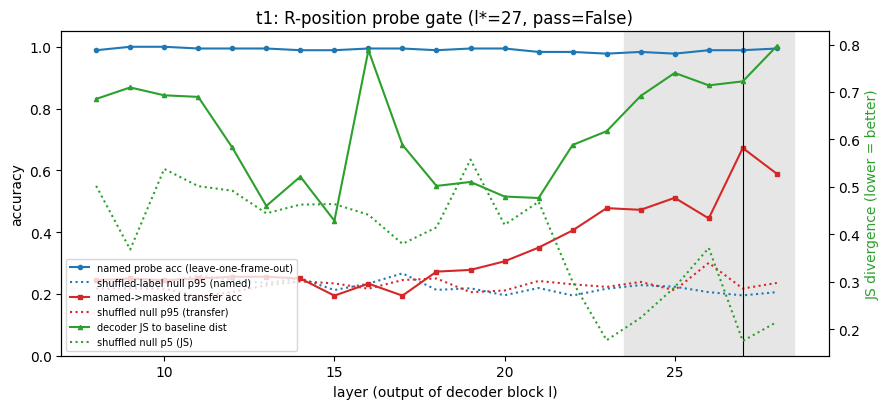

l*=27: named 0.99 (null p95 0.20), transfer 0.67 (null p95 0.22), decoder JS 0.722 (null p5 0.175); baseline decodes as {'bfs': 0.12, 'dfs': 0.6, 'bidir_bfs': 0.0, 'iddfs': 0.0, 'astar': 0.0, 'dijkstra_unit': 0.27}


In [19]:
# ---- analysis/analyze.py: E3 gate figure (verbatim; notebook changes: one panel per task in TASKS, shown inline
#      instead of saved to figures/gate_per_layer.{png,pdf})
def fig_gate(gate):
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, len(TASKS), figsize=(6 * len(TASKS) + 3, 4.2), sharey=False)  # original: (1, 2, figsize=(12, 4.2))
    axes = np.atleast_1d(axes)
    for ax, t in zip(axes, TASKS):
        pl = gate[t]["per_layer"]
        L = [p["layer"] for p in pl]
        ax.plot(L, [p["named_acc"] for p in pl], "-o", ms=3, label="named probe acc (leave-one-frame-out)", color="#1f77b4")
        ax.plot(L, [p["null_named_p95"] for p in pl], ":", color="#1f77b4", label="shuffled-label null p95 (named)")
        ax.plot(L, [p["transfer_acc"] for p in pl], "-s", ms=3, label="named->masked transfer acc", color="#d62728")
        ax.plot(L, [p["null_transfer_p95"] for p in pl], ":", color="#d62728", label="shuffled null p95 (transfer)")
        ax2 = ax.twinx()
        ax2.plot(L, [p["decoder_js"] for p in pl], "-^", ms=3, color="#2ca02c", label="decoder JS to baseline dist")
        ax2.plot(L, [p["null_js_p5"] for p in pl], ":", color="#2ca02c", label="shuffled null p5 (JS)")
        ax2.set_ylabel("JS divergence (lower = better)", color="#2ca02c")
        ax.axvspan(min(gate[t]["band"]) - 0.5, max(gate[t]["band"]) + 0.5, color="0.9", zorder=0)
        ax.axvline(gate[t]["l_star"], color="k", lw=0.8)
        ax.set_title(f"{t}: R-position probe gate (l*={gate[t]['l_star']}, pass={gate[t]['gate_pass']})")
        ax.set_xlabel("layer (output of decoder block l)")
        ax.set_ylabel("accuracy")
        ax.set_ylim(0, 1.05)
        if t == TASKS[0]:
            h1, l1 = ax.get_legend_handles_labels()
            h2, l2 = ax2.get_legend_handles_labels()
            ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="lower left")
    fig.tight_layout()
    plt.show()


fig_gate(gate)
best = next(p for p in gate["t1"]["per_layer"] if p["layer"] == gate["t1"]["l_star"])
print(f"l*={gate['t1']['l_star']}: named {best['named_acc']:.2f} (null p95 {best['null_named_p95']:.2f}), transfer "
      f"{best['transfer_acc']:.2f} (null p95 {best['null_transfer_p95']:.2f}), decoder JS {best['decoder_js']:.3f} "
      f"(null p5 {best['null_js_p5']:.3f}); baseline decodes as",
      {m: round(x, 2) for m, x in zip(CATALOGUE["t1"], best["decoder_dist"])})

### E4: the path-search manifold, and where the ban sends the model
**First figure: the forced-prompt states at layer 27, drawn two ways.**
* **Left:** the geodesic MDS map.
* **Right:** a PCA-2D view of the same states.
* **Big circles:** the mode centroids, coloured by log10(1 + the baseline's implemented count).
* **Markers:** ★ baseline, ▼ `ban:bfs`, ▲ `mention:bfs`. The arrow runs from mention to ban.
* **Dark red line:** the succession path.
* **✕:** the baseline after the Phase-D affine directional ablation of the BFS direction.

**Second figure: where the samples land.** For baseline, `ban:bfs` and `mention:bfs`, each mode's implemented count is drawn as a bubble at that mode's centroid on the geodesic map.

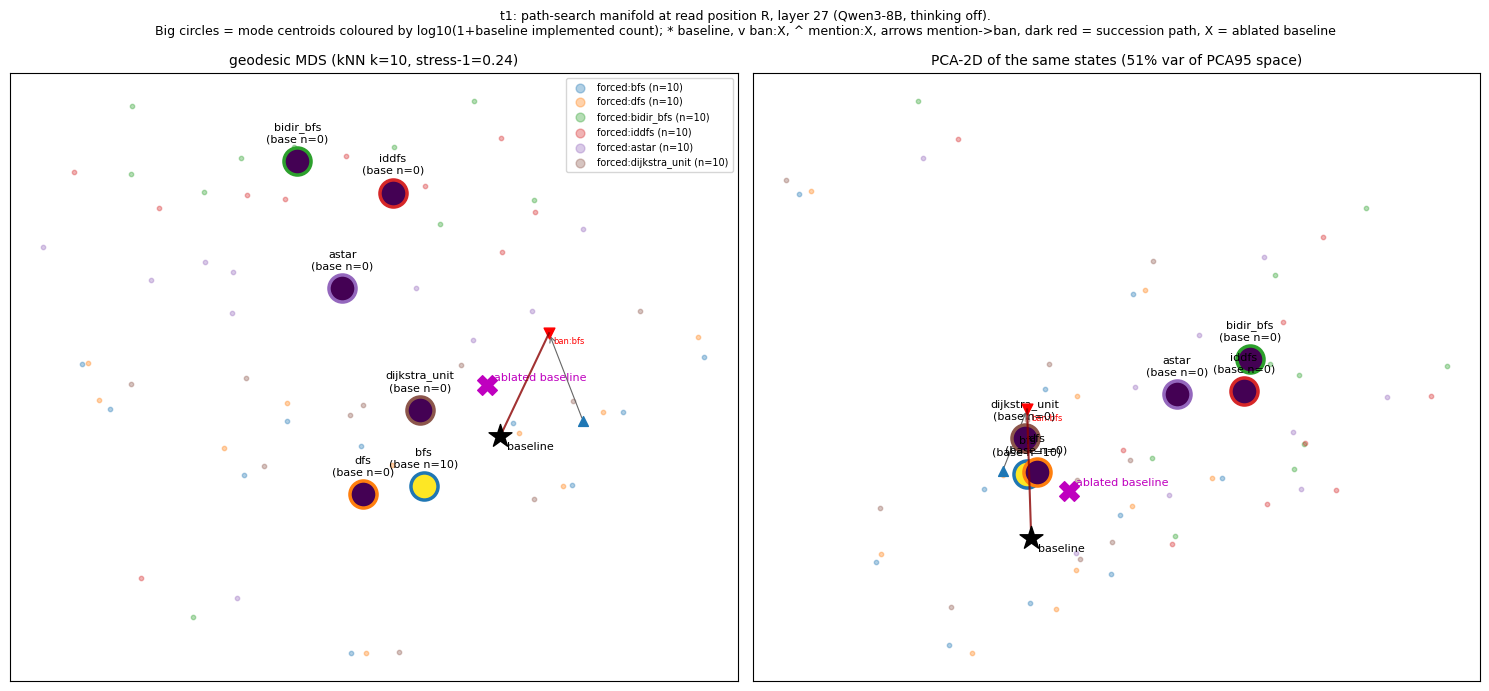

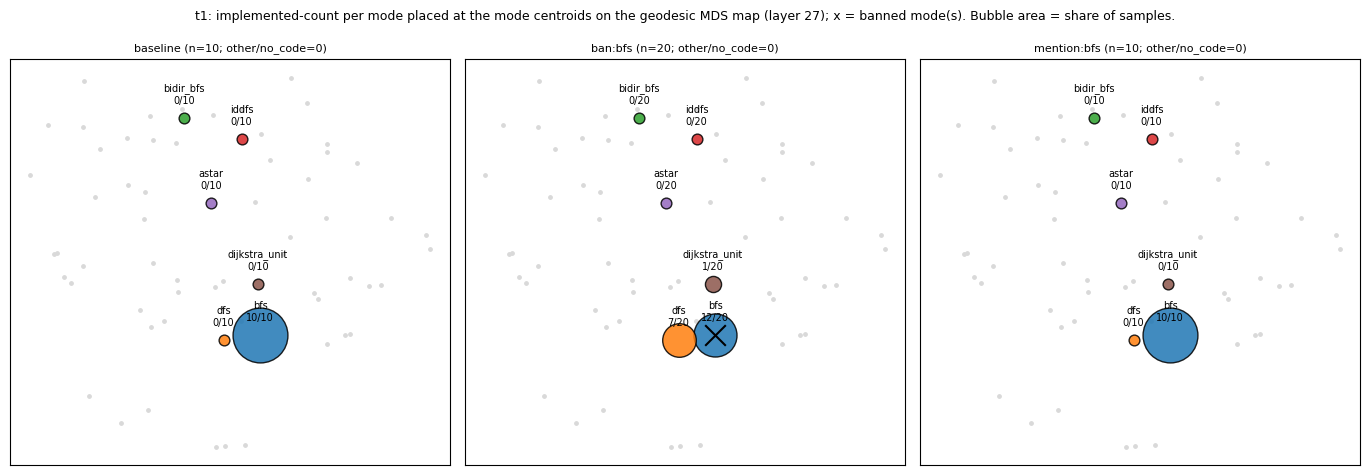

                                              demo  full run
PCA95 dims                                   14.00     22.00
MDS stress-1                                  0.24      0.22
geodesic vs Euclidean Spearman                0.89      0.87
TwoNN intrinsic dimension                     3.49      4.16
TwoNN, column-shuffled null mean              8.98     11.92
checks (geodesic >= Euclidean, symmetric): {'geodesic_ge_euclidean_all_pairs': True, 'symmetric_max_abs_diff': 2.842170943040401e-14}


In [20]:
# ---- analysis/analyze.py: E4 manifold (verbatim; notebook changes: KNN_K / MDS_N_INIT / N_TWONN_NULLS from the config
#      cell, the ablated-baseline state comes from `data` instead of cache/hR_ablated_t1.npz, and the figures are shown
#      inline instead of saved to figures/manifold_t1.* and figures/ban_shift_on_manifold_t1.*)
def manifold(index, H, gate, summA, geoB, phaseC, rows=None) -> dict:
    import matplotlib.pyplot as plt
    from scipy.stats import spearmanr
    from sklearn.manifold import MDS

    out = {}
    for t in TASKS:
        cat = CATALOGUE[t]
        l = gate[t]["l_star"]
        iN = [i for i, r in enumerate(index) if r["task"] == t and r["condition"].startswith("forced:")]
        lab = [index[i]["condition"].split(":")[1] for i in iN]
        Xn = H[l][iN]
        mu, comps, ev = pca95(Xn)
        P = (Xn - mu) @ comps.T
        C = np.stack([Xn[[k for k, m in enumerate(lab) if m == mm]].mean(0) for mm in cat])
        G, ginfo = knn_graph(P, KNN_K)
        # leaf points: centroids, baseline, ban:X, mention:X, listall, succession, ablated baseline
        leaf_names, leaf_vecs = [], []
        for j, m in enumerate(cat):
            leaf_names.append(f"centroid:{m}")
            leaf_vecs.append(C[j])

        def mean_cond(c):
            ii = [i for i, r in enumerate(index) if r["task"] == t and r["condition"] == c]
            return H[l][ii].mean(0) if ii else None

        conds = ["baseline", "listall"] + [f"ban:{m}" for m in cat] + [f"mention:{m}" for m in cat]
        chain = phaseC.get("succession", {}).get(t, {}).get("chain", [])
        for k in range(2, len(chain) + 1):
            conds.append("ban:" + "+".join(chain[:k]))
        for c in conds:
            v = mean_cond(c)
            if v is not None:
                leaf_names.append(c)
                leaf_vecs.append(v)
        abl = data["metadata"].get("hR_ablated_baseline_mean_l27")  # original: CACHE / f"hR_ablated_{t}.npz"
        if abl is not None and l == data["metadata"]["hR_layer"]:  # original: if l in band of the npz
            leaf_names.append("ablated_baseline")
            leaf_vecs.append(np.array(abl, np.float32))  # = Z["h"][band.index(l)].astype(np.float32).mean(0)
        Q = (np.stack(leaf_vecs) - mu) @ comps.T
        GA = attach(G, P, Q, KNN_K)
        from scipy.sparse.csgraph import shortest_path

        Dall = shortest_path(GA, directed=False)
        Dall = (Dall + Dall.T) / 2
        finite = np.isfinite(Dall).all()
        mds = MDS(n_components=2, dissimilarity="precomputed", n_init=MDS_N_INIT, random_state=0, normalized_stress="auto")
        Y = mds.fit_transform(np.where(np.isfinite(Dall), Dall, np.nanmax(Dall[np.isfinite(Dall)]) * 2))
        from scipy.spatial.distance import pdist, squareform

        Dy = squareform(pdist(Y))
        iu = np.triu_indices(len(Dall), 1)
        stress1 = float(np.sqrt(np.sum((Dall[iu] - Dy[iu]) ** 2) / np.sum(Dall[iu] ** 2)))
        # geodesic vs euclidean rank correlation (over points)
        from scipy.spatial.distance import cdist

        De = cdist(P, P)
        npnt = len(P)
        ii = np.triu_indices(npnt, 1)
        rho = float(spearmanr(Dall[:npnt, :npnt][ii], De[ii])[0])
        # testing plan 8: geodesic >= Euclidean for every pair, symmetric distance matrix
        Graw = shortest_path(GA, directed=False)
        geo_checks = {"geodesic_ge_euclidean_all_pairs": bool((Dall[:npnt, :npnt] + 1e-4 >= De).all()),
                      "symmetric_max_abs_diff": float(np.nanmax(np.abs(Graw - Graw.T)[np.isfinite(Graw)]))}
        # intrinsic dimension vs column-shuffled nulls
        idim = twonn_id(P)
        nulls = []
        for s in range(N_TWONN_NULLS):
            Ps = P.copy()
            for c in range(Ps.shape[1]):
                Ps[:, c] = RNG.permutation(Ps[:, c])
            nulls.append(twonn_id(Ps))
        counts = {m: summA[t]["baseline_label_counts"].get(m, 0) for m in cat}
        out[t] = {"layer": l, "pca_dims": int(comps.shape[0]), "pca_explained": float(ev.sum()), "graph": ginfo,
                  "mds_stress1": stress1, "geodesic_vs_euclidean_spearman": rho, "twonn_id": idim,
                  "twonn_null_mean": float(np.nanmean(nulls)), "twonn_null_p5_p95": [float(np.nanpercentile(nulls, 5)),
                                                                                       float(np.nanpercentile(nulls, 95))],
                  "leaf_names": leaf_names, "mds_xy_leaves": Y[npnt:].tolist(), "all_finite": bool(finite),
                  "centroid_geodesic": Dall[npnt:npnt + len(cat), npnt:npnt + len(cat)].tolist(),
                  "baseline_counts": counts, "checks": geo_checks}
        # ---------------------------------------------------------------- figure: MDS + PCA side by side
        cmap = plt.get_cmap("tab10")
        fig, axes = plt.subplots(1, 2, figsize=(15, 7.0))
        Ppca = P[:, :2]
        Qpca = Q[:, :2]
        for ax, (pts, lv, title) in zip(axes, [(Y[:npnt], Y[npnt:], f"geodesic MDS (kNN k=10, stress-1={stress1:.2f})"),
                                               (Ppca, Qpca, f"PCA-2D of the same states ({ev[:2].sum() * 100:.0f}% var of PCA95 space)")]):
            for j, m in enumerate(cat):
                sel = [k for k, mm in enumerate(lab) if mm == m]
                ax.scatter(pts[sel, 0], pts[sel, 1], s=10, alpha=0.35, color=cmap(j), label=f"forced:{m} (n={len(sel)})")
            vmax = max(np.log10(1 + max(counts.values())), 1e-6)
            for j, m in enumerate(cat):
                c = math.log10(1 + counts[m]) / vmax
                ax.scatter(lv[j, 0], lv[j, 1], s=380, marker="o", c=[plt.get_cmap("viridis")(c)], edgecolors=cmap(j),
                           linewidths=2.5, zorder=5)
                ax.annotate(f"{m}\n(base n={counts[m]})", lv[j], fontsize=8, ha="center", va="bottom",
                            xytext=(0, 12), textcoords="offset points", zorder=6)
            name_pos = {n: lv[k] for k, n in enumerate(leaf_names)}
            for n, p in name_pos.items():
                if n.startswith("centroid"):
                    continue
                if n == "baseline":
                    ax.scatter(*p, marker="*", s=300, c="k", zorder=7)
                    ax.annotate("baseline", p, fontsize=8, xytext=(5, -10), textcoords="offset points")
                elif n == "listall":
                    ax.scatter(*p, marker="P", s=120, c="0.3", zorder=7)
                    ax.annotate("list-all", p, fontsize=7, xytext=(5, 3), textcoords="offset points")
                elif n == "ablated_baseline":
                    ax.scatter(*p, marker="X", s=200, c="m", zorder=7)
                    ax.annotate("ablated baseline", p, fontsize=8, color="m", xytext=(5, 3), textcoords="offset points")
                elif n.startswith("ban:") and "+" not in n:
                    ax.scatter(*p, marker="v", s=60, c="r", zorder=6)
                    ax.annotate(n, p, fontsize=6, color="r", xytext=(3, -8), textcoords="offset points")
                elif n.startswith("ban:"):
                    ax.scatter(*p, marker="D", s=50, c="darkred", zorder=6)
                elif n.startswith("mention:"):
                    ax.scatter(*p, marker="^", s=50, c="tab:blue", zorder=6)
            for m in cat:
                a, b = name_pos.get(f"mention:{m}"), name_pos.get(f"ban:{m}")
                if a is not None and b is not None:
                    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color="0.4", lw=0.8))
            path = ["baseline"] + ["ban:" + "+".join(chain[:k]) for k in range(1, len(chain) + 1)]
            path = [name_pos[p] for p in path if p in name_pos]
            if len(path) >= 2:
                pa = np.array(path)
                ax.plot(pa[:, 0], pa[:, 1], "-", color="darkred", lw=1.5, alpha=0.8, zorder=6)
            ax.set_title(title, fontsize=10)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[0].legend(fontsize=7, loc="best", markerscale=2)
        fig.suptitle(f"{t}: path-search manifold at read position R, layer {l} (Qwen3-8B, thinking off).\nBig circles = "
                     f"mode centroids coloured by log10(1+baseline implemented count); * baseline, v ban:X, ^ mention:X, "
                     f"arrows mention->ban, dark red = succession path, X = ablated baseline", fontsize=9)
        fig.tight_layout()
        plt.show()
        # ---------------------------------------------------------------- figure: where do the bans send the model?
        if rows is not None:
            X1 = summA[t]["modal"]
            ban_conds = sorted({r["condition"] for r in rows["C"] if r["task"] == t and r["condition"].startswith("ban:")},
                               key=lambda c: (c.count("+"), c))
            panels = [("baseline", [r for r in rows["A"] if r["task"] == t and r["condition"] == "baseline"])]
            panels += [(c, [r for r in rows["C"] if r["task"] == t and r["condition"] == c]) for c in ban_conds]
            mcond = f"mention:{X1}"
            mr = [r for r in rows["C"] if r["task"] == t and r["condition"] == mcond]
            if mr:
                panels.append((mcond, mr))
            fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 4.8), squeeze=False)
            for ax, (c, rr) in zip(axes[0], panels):
                cnt = Counter(r["label"] for r in rr)
                ax.scatter(Y[:npnt, 0], Y[:npnt, 1], s=6, c="0.85")
                for j, m in enumerate(cat):
                    k = cnt.get(m, 0)
                    ax.scatter(Y[npnt + j, 0], Y[npnt + j, 1], s=60 + 1500 * k / max(len(rr), 1), color=cmap(j),
                               alpha=0.85, edgecolors="k", zorder=5)
                    ax.annotate(f"{m}\n{k}/{len(rr)}", (Y[npnt + j, 0], Y[npnt + j, 1]), fontsize=7, ha="center",
                                va="bottom", xytext=(0, 9), textcoords="offset points", zorder=6)
                banned = c.split(":", 1)[1].split("+") if c.startswith("ban:") else []
                for b in banned:
                    jb = cat.index(b)
                    ax.scatter(Y[npnt + jb, 0], Y[npnt + jb, 1], marker="x", s=220, c="k", zorder=7)
                oth = cnt.get("other", 0) + cnt.get("no_code", 0)
                ax.set_title(f"{c} (n={len(rr)}; other/no_code={oth})", fontsize=8)
                ax.set_xticks([])
                ax.set_yticks([])
            fig.suptitle(f"{t}: implemented-count per mode placed at the mode centroids on the geodesic MDS map "
                         f"(layer {l}); x = banned mode(s). Bubble area = share of samples.", fontsize=9)
            fig.tight_layout()
            plt.show()
    return out


man = manifold(index, H, gate, summA, geo_out, phaseC, rows)
m_, ref_man = man["t1"], data["metadata"]["full_run_reference"]["manifold_t1"]
print(f"{'':<40}{'demo':>10}{'full run':>10}")
for key, label in (("pca_dims", "PCA95 dims"), ("mds_stress1", "MDS stress-1"),
                   ("geodesic_vs_euclidean_spearman", "geodesic vs Euclidean Spearman"),
                   ("twonn_id", "TwoNN intrinsic dimension"), ("twonn_null_mean", "TwoNN, column-shuffled null mean")):
    print(f"{label:<40}{m_[key]:>10.2f}{ref_man[key]:>10.2f}")
print("checks (geodesic >= Euclidean, symmetric):", m_["checks"])

### E5: the forecast contest
Each forecast is scored against the ban samples in two ways:
* **Top-1 hit:** did the forecast's top mode match the realised mode? A mode counts as realised only if it leads by at least 15% of the compliant samples.
* **Mean log score:** the average log probability the forecast gives to the displaced samples. To keep it finite, the forecast is smoothed as `0.98 · (0.95 q + 0.05/K)`, and `other` gets 0.02.

Two sets of forecasts are scored on the 20 demo `ban:bfs` samples: the **committed** forecasts (hash `186f71…`) and the forecasts the demo **recomputed** from its own states. For reference, the full run's scores of the committed forecasts on all 100 samples are shown alongside. The contest also checks the commit's integrity: the first ban sample must be dated after the commit.

In [21]:
# ---- analysis/analyze.py: E5 contest (score_event, contest and contest_aggregate verbatim; the per-event bookkeeping
#      loop is the one in analyze.main())
PREDS = ["association", "frequency", "geodesic", "decoder"]


def score_event(ev: dict, rr: list[dict], cat: list[str]) -> dict:
    S = ev["survivors"]
    bset = ev["banset"]
    comp = [r for r in rr if r["passed"] and r["label"] not in bset and r["label"] != "no_code"]
    cnt = Counter(r["label"] for r in comp)
    real = np.array([cnt.get(m, 0) for m in S], float)
    lead_ok = False
    ranked = cnt.most_common()
    if ranked:
        lead = (ranked[0][1] - (ranked[1][1] if len(ranked) > 1 else 0)) / max(len(comp), 1)
        lead_ok = lead >= 0.15
    realised = ranked[0][0] if (ranked and lead_ok) else None
    out = {"n": len(rr), "n_compliant": len(comp), "compliance": len(comp) / max(len(rr), 1),
           "realised_counts": dict(cnt), "realised_mode": realised or "no clear mode",
           "realised_in_survivors": realised in S if realised else None, "predictors": {}}
    scored = [r for r in rr if r["label"] in S or r["label"] == "other"]
    for p in PREDS + ["association_X1"]:
        q = np.array([ev["distributions"][p][m] for m in S])
        top1 = S[int(np.argmax(q))]
        qm = 0.98 * (0.95 * q + 0.05 / len(S))
        lp = [math.log(qm[S.index(r["label"])]) if r["label"] in S else math.log(0.02) for r in scored]
        rs = real + 0.5
        js = js_div(q, rs / rs.sum())
        from scipy.stats import spearmanr

        sp = float(spearmanr(q, real)[0]) if len(S) > 2 and real.std() > 0 and q.std() > 0 else float("nan")
        top2p = set(np.array(S)[np.argsort(-q)[:2]])
        top2r = set(np.array(S)[np.argsort(-real)[:2]])
        tied = bool(ev.get("top1_tied", {}).get(p, False))
        out["predictors"][p] = {"top1": top1, "tied": tied,
                                "hit": (None if tied else ((top1 == realised) if realised else False)),
                                "log_score_mean": float(np.mean(lp)) if lp else float("nan"), "n_scored": len(lp),
                                "js_to_realised": js, "spearman": sp, "top2_agreement": len(top2p & top2r) / 2}
    return out


def contest(rows, preds, phaseC) -> dict:
    events = {}
    for eid, ev in preds["events"].items():
        t = ev["task"]
        cat = CATALOGUE[t]
        if ev["kind"] == "ban":
            cond = "ban:" + "+".join(ev["banset"])
            rr = [r for r in rows["C"] if r["task"] == t and r["condition"] == cond]
        else:
            # removal event scored on the strongest successful d_X arm (filled in by c2)
            continue
        if not rr:
            continue
        sc = score_event(ev, rr, cat)
        per_para = {}
        for pid in sorted({r["paraphrase_id"] for r in rr}):
            rp = [r for r in rr if r["paraphrase_id"] == pid]
            per_para[pid] = {"n": len(rp), "compliant": sum(r["passed"] and r["label"] not in ev["banset"] and r["label"] != "no_code" for r in rp),
                             "labels": dict(Counter(r["label"] for r in rp))}
        sc["per_paraphrase"] = per_para
        sc["exploratory"] = bool(phaseC.get("events", {}).get(eid, {}).get("exploratory", False))
        sc["ban_failure"] = sc["compliance"] < 0.5
        sc.update({"event": eid, "task": t, "banset": ev["banset"], "survivors": ev["survivors"],
                   "committed_top1": ev["top1"], "concordance": ev["concordance"], "stability": ev["stability"],
                   "ambiguity_flag": ev["ambiguity_flag"]})
        events[eid] = sc
    return events


def contest_aggregate(events: dict, primary_only: bool = False) -> dict:
    agg = {}
    sc = [e for e in events.values() if not (primary_only and e.get("exploratory"))]
    for p in PREDS + ["association_X1"]:
        scored = [e for e in sc if e["predictors"][p]["hit"] is not None]
        hits = sum(bool(e["predictors"][p]["hit"]) for e in scored)
        n = len(scored)
        agg[p] = {"hits": hits, "events": n, "events_tied_excluded": len(sc) - n, "hit_rate": hits / max(n, 1),
                  "wilson": wilson(hits, n),
                  "mean_log_score": float(np.nanmean([e["predictors"][p]["log_score_mean"] for e in sc])) if sc else None,
                  "mean_js": float(np.nanmean([e["predictors"][p]["js_to_realised"] for e in sc])) if sc else None,
                  "mean_top2": float(np.nanmean([e["predictors"][p]["top2_agreement"] for e in sc])) if sc else None}
    trio = ["association", "frequency", "geodesic"]
    M = {a: {b: float(np.mean([e["committed_top1"][a] == e["committed_top1"][b] for e in sc])) if sc else None
             for b in trio} for a in trio}
    return {"per_predictor": agg, "agreement_matrix_top1": M, "n_events": len(sc),
            "note": "descriptive only: about 4-7 events, no p-values"}


commit = data["metadata"]["predictions"]["commit"]  # full run: the last line of predictions/commit_log.jsonl
contest_runs = {}
for name, preds in (("committed", data["metadata"]["predictions"]), ("demo", preds_demo)):
    ce = contest(rows, preds, phaseC)
    for eid, e in ce.items():  # the bookkeeping of analyze.main()
        e["commit_sha256"] = commit["sha256"]
        e["distributions"] = preds["events"][eid]["distributions"]
        e["hits"] = {p: e["predictors"][p]["hit"] for p in PREDS}
        first = min(r["utc"] for r in rows["C"] if f"{e['task']}|ban:{'+'.join(e['banset'])}" == r.get("event_tag"))
        e["first_sample_after_commit"] = bool(first > commit["unix"])
    contest_runs[name] = {"events": ce, "aggregate": contest_aggregate(ce)}

ev_c = contest_runs["committed"]["events"]["t1|ban:bfs"]
ev_d = contest_runs["demo"]["events"]["t1|ban:bfs"]
ev_f = data["metadata"]["full_run_reference"]["contest_event_t1_ban_bfs"]
print(f"t1|ban:bfs on the demo samples: n={ev_c['n']}, compliant {ev_c['n_compliant']} ({ev_c['compliance']:.2f}), "
      f"realised counts {ev_c['realised_counts']}, realised mode: {ev_c['realised_mode']}, "
      f"first sample after the commit: {ev_c['first_sample_after_commit']}")
print(f"t1|ban:bfs in the full run:     n={ev_f['n']}, compliant {ev_f['n_compliant']} ({ev_f['compliance']:.2f}), "
      f"realised counts {ev_f['realised_counts']}, realised mode: {ev_f['realised_mode']}\n")
print(f"{'predictor':<15}{'committed: top1':<20}{'hit':<7}{'log score':>10}{'demo-recomputed: top1':>25}{'hit':>6}"
      f"{'log score':>11}{'full run (n=100) log score':>29}")
for p in PREDS + ["association_X1"]:
    c_, d_, f_ = ev_c["predictors"][p], ev_d["predictors"][p], ev_f["predictors"][p]
    print(f"{p:<15}{c_['top1']:<20}{str(c_['hit']):<7}{c_['log_score_mean']:>10.2f}{d_['top1']:>25}{str(d_['hit']):>6}"
          f"{d_['log_score_mean']:>11.2f}{f_['log_score_mean']:>29.2f}")
agg_full = data["metadata"]["full_run_reference"]["contest_aggregate_primary"]["per_predictor"]
print("\nfull run, primary events (t1|ban:bfs and t2|ban:dijkstra), mean log score:",
      {p: round(v["mean_log_score"], 2) for p, v in agg_full.items()})

t1|ban:bfs on the demo samples: n=20, compliant 2 (0.10), realised counts {'dfs': 1, 'dijkstra_unit': 1}, realised mode: no clear mode, first sample after the commit: True
t1|ban:bfs in the full run:     n=100, compliant 18 (0.18), realised counts {'dijkstra_unit': 8, 'dfs': 10}, realised mode: no clear mode

predictor      committed: top1     hit     log score    demo-recomputed: top1   hit  log score   full run (n=100) log score
association    astar               False       -3.87                    astar False      -3.87                        -3.54
frequency      dfs                 None        -1.63                      dfs  None      -1.63                        -1.63
geodesic       dfs                 False       -1.31                      dfs False      -1.38                        -1.34
decoder        dfs                 False       -0.90                      dfs False      -0.88                        -1.29
association_X1 astar               False       -3.87                 

## 8. Results at a glance
The table and figure below put the demo next to the full run:
* **(a)** label shares per condition;
* **(b)** where the displaced `ban:bfs` mass lands, plotted against each mode's geodesic distance from the BFS centroid;
* **(c)** the mean log score of each forecast on `ban:bfs`.

The full run's activation-removal arm (Phase D, GPU) is summarised in the last lines of the table. Phase D applied an affine directional ablation of the BFS direction at α = 0.5, 1 and 2. It moved 0 of 50 samples at every α, and 78–90% of the outputs stayed byte-identical to α = 0, the same as for random directions with identical edit norms. The verdict was *"untestable (removal unsuccessful at the tested coefficients)"*.

                                            demo                                                full run
baseline label counts                       {'bfs': 10} (n=10)                                  {'bfs': 200} (n=200)
mention:bfs label counts                    {'bfs': 10} (n=10)                                  {'bfs': 50} (n=50)
ban:bfs label counts                        {'dfs': 7, 'bfs': 12, 'dijkstra_unit': 1} (n=20)    {'dfs': 29, 'bfs': 62, 'dijkstra_unit': 9} (n=100)
baseline pass rate / compliance / hill_cc   1.00 / 1.00 / 1.00                                  0.99 / 0.99 / 1.00
ban:bfs pass rate / compliance / hill_cc    0.65 / 0.10 / 1.71                                  0.76 / 0.18 / 2.03
geodesic BFS -> dfs, dijkstra_unit          44.6, 50.1                                          41.2, 58.4
geodesic BFS -> astar, iddfs, bidir_bfs     73.4, 78.5, 83.8                                    71.1, 81.7, 94.9
TwoNN ID (column-shuffled null mean)        3.49 (8.98)           

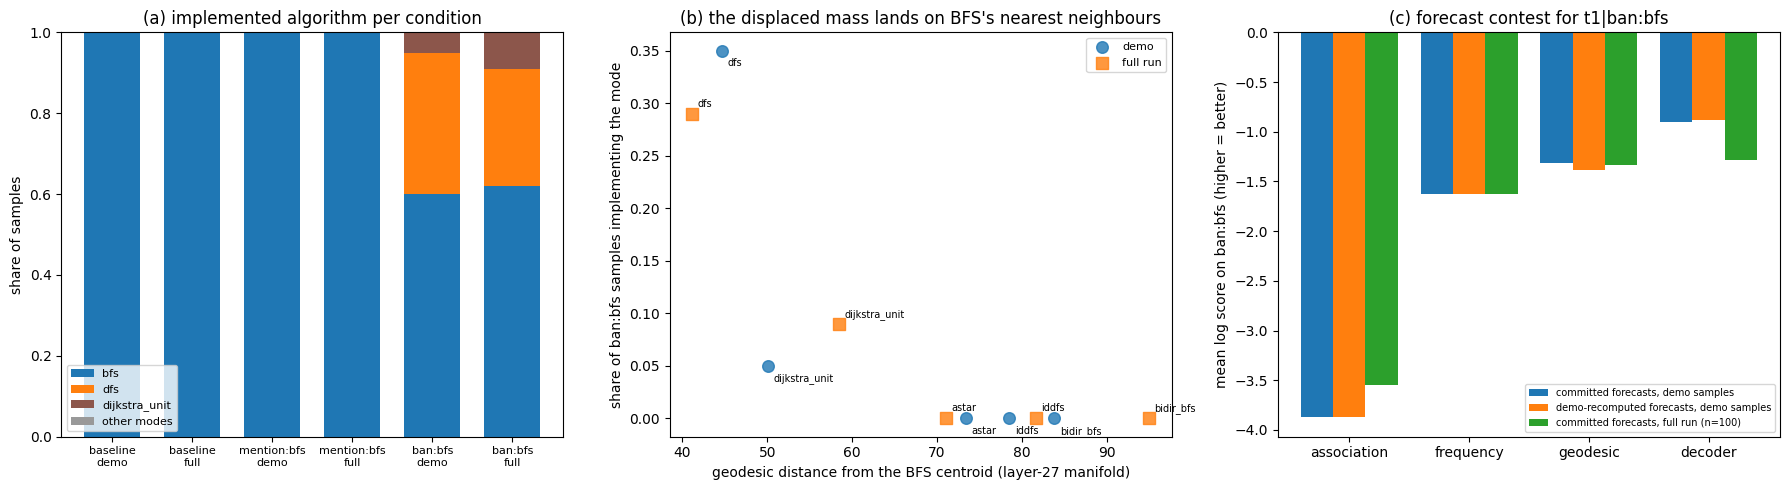

In [22]:
cat = CATALOGUE["t1"]
ref = data["metadata"]["full_run_reference"]
full_s = ref["summaries_t1"]
geo_full = ref["manifold_t1"]["centroid_geodesic"][ib]  # full-run geodesic distances from the BFS centroid

# ---------------------------------------------------------------- key numbers, demo vs full run
print(f"{'':<44}{'demo':<52}full run")
for c in ("baseline", "mention:bfs", "ban:bfs"):
    d, f = summ["t1"][c], full_s[c]
    demo_counts = f"{d['label_counts']} (n={d['n']})"
    print(f"{c + ' label counts':<44}{demo_counts:<52}{f['label_counts']} (n={f['n']})")
for c in ("baseline", "ban:bfs"):
    d, f = summ["t1"][c], full_s[c]
    demo_rates = f"{d['pass_rate']:.2f} / {d['compliance']:.2f} / {d['hill_cc']:.2f}"
    print(f"{c + ' pass rate / compliance / hill_cc':<44}{demo_rates:<52}"
          f"{f['pass_rate']:.2f} / {f['compliance']:.2f} / {f['hill_cc']:.2f}")
for group in (("dfs", "dijkstra_unit"), ("astar", "iddfs", "bidir_bfs")):
    demo_d = ", ".join(f"{Dc[ib][cat.index(m)]:.1f}" for m in group)
    print(f"{'geodesic BFS -> ' + ', '.join(group):<44}{demo_d:<52}" + ", ".join(f"{geo_full[cat.index(m)]:.1f}" for m in group))
demo_id = f"{man['t1']['twonn_id']:.2f} ({man['t1']['twonn_null_mean']:.2f})"
print(f"{'TwoNN ID (column-shuffled null mean)':<44}{demo_id:<52}"
      f"{ref['manifold_t1']['twonn_id']:.2f} ({ref['manifold_t1']['twonn_null_mean']:.2f})")
print(f"{'labeller re-run: labels equal to full run':<44}{sum(same)}/{len(same)}")
c2 = ref["c2_removal_t1"]
print(f"\nPhase D (full run, GPU), removal of the '{c2['modal']}' direction: verdict = {c2['verdict']}")
for a, v in sorted(c2["arms"].items(), key=lambda kv: (kv[1]["exploratory"], kv[0])):
    ident = v["identical_text_vs_alpha0_frac"]
    print(f"  {a:<16} alpha={v['alpha']:<4} n={v['n']:<3} moved={v['moved_frac']:.2f}  pass={v['pass_rate']:.2f}  "
          f"identical text vs alpha=0: {'-' if ident is None else round(ident, 2)}{'  (exploratory)' if v['exploratory'] else ''}")

# ---------------------------------------------------------------- figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cols = {"bfs": "#1f77b4", "dfs": "#ff7f0e", "dijkstra_unit": "#8c564b", "other modes": "0.6"}
ax = axes[0]
bars = [(f"{c}\n{src}", summ_src[c]) for c in ("baseline", "mention:bfs", "ban:bfs")
        for src, summ_src in (("demo", summ["t1"]), ("full", full_s))]
x = np.arange(len(bars))
bottom = np.zeros(len(bars))
for lab_, col in cols.items():
    v = np.array([(sum(s_["label_counts"].get(m, 0) for m in cat if m not in ("bfs", "dfs", "dijkstra_unit"))
                   + s_["label_counts"].get("other", 0) + s_["label_counts"].get("no_code", 0)
                   if lab_ == "other modes" else s_["label_counts"].get(lab_, 0)) / s_["n"] for _, s_ in bars])
    ax.bar(x, v, bottom=bottom, color=col, label=lab_, width=0.7)
    bottom += v
ax.set_xticks(x)
ax.set_xticklabels([b[0] for b in bars], fontsize=8)
ax.set_ylabel("share of samples")
ax.set_title("(a) implemented algorithm per condition")
ax.legend(fontsize=8, loc="lower left")

ax = axes[1]
S = [m for m in cat if m != "bfs"]
for src, D_bfs, cnt_, n_, mk, dy in (("demo", Dc[ib], summ["t1"]["ban:bfs"]["label_counts"], summ["t1"]["ban:bfs"]["n"], "o", -11),
                                     ("full run", geo_full, full_s["ban:bfs"]["label_counts"], full_s["ban:bfs"]["n"], "s", 5)):
    xs = [D_bfs[cat.index(m)] for m in S]
    ys = [cnt_.get(m, 0) / n_ for m in S]
    ax.scatter(xs, ys, s=70, marker=mk, label=src, alpha=0.8)
    for m, xx, yy in zip(S, xs, ys):
        ax.annotate(m, (xx, yy), fontsize=7, xytext=(4, dy), textcoords="offset points")
ax.set_xlabel("geodesic distance from the BFS centroid (layer-27 manifold)")
ax.set_ylabel("share of ban:bfs samples implementing the mode")
ax.set_title("(b) the displaced mass lands on BFS's nearest neighbours")
ax.legend(fontsize=8)

ax = axes[2]
labels_ = ["association", "frequency", "geodesic", "decoder"]
xx = np.arange(len(labels_))
w = 0.27
for k_, (src, vals) in enumerate((("committed forecasts, demo samples", [ev_c["predictors"][p]["log_score_mean"] for p in labels_]),
                                  ("demo-recomputed forecasts, demo samples", [ev_d["predictors"][p]["log_score_mean"] for p in labels_]),
                                  ("committed forecasts, full run (n=100)", [ev_f["predictors"][p]["log_score_mean"] for p in labels_]))):
    ax.bar(xx + (k_ - 1) * w, vals, w, label=src)
ax.set_xticks(xx)
ax.set_xticklabels(labels_)
ax.set_ylabel("mean log score on ban:bfs (higher = better)")
ax.set_title("(c) forecast contest for t1|ban:bfs")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()